# BAB 1. Pengantar CRISP-DM untuk Clustering

## menginstal pustaka (library) Python tambahan

In [1]:
!pip -q install pandas numpy matplotlib seaborn scikit-learn openpyxl

# BAB 2. Dataset dan Persiapan Lingkungan

## Mengunduh dan membaca data

In [2]:
import pandas as pd
import numpy as np
import matplotlib.pyplot as plt
import seaborn as sns
from pathlib import Path
from zipfile import ZipFile
import requests, io

url = "https://archive.ics.uci.edu/static/public/352/online+retail.zip"
response = requests.get(url, timeout=60)
response.raise_for_status()

with ZipFile(io.BytesIO(response.content)) as z:
    files = z.namelist()
    print("Isi ZIP:", files)
    excel_file = next(name for name in files if name.lower().endswith((".xlsx", ".xls")))
    with z.open(excel_file) as f:
        df = pd.read_excel(f)

print(df.shape)
df.head()

Isi ZIP: ['Online Retail.xlsx']
(541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


## Menyamakan nama kolom

In [3]:
df.columns = [c.strip() for c in df.columns]
df.head()
df.info()

<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


# Tugas Awal

- jumlah barisnya adalah 541.909 baris dan jumlah kolomnya adalah 8 kolom.
- Kolom Numerik: Quantity dan UnitPrice (berisi angka kuantitas barang dan harga).   
- Kolom Kategorikal: Description dan Country (berisi teks nama produk dan negara).   
- Kolom Tanggal (Datetime): InvoiceDate (berisi informasi waktu transaksi).   
- Kolom Pengenal (Identifier): InvoiceNo,CustomerID, dan StockCode (berisi kode unik faktur dan nomor pelanggan).
- Karena CustomerID hanyalah nomor identitas atau pengenal unik untuk membedakan satu pelanggan dengan pelanggan lainnya. CustomerID tidak merepresentasikan pola atau perilaku belanja. Algoritma clustering membutuhkan fitur perilaku (seperti seberapa baru, seberapa sering, dan berapa total belanja yang dihitung dalam bentuk RFM), bukan nomor ID-nya.
- Berdasarkan data pada kolom InvoiceDate di gambar tersebut, catatan transaksinya dimulai pada tanggal 1 Desember 2010 (2010-12-01), dan versi Colabnya dikerjakan 1 November 2026

# PRAKTIKUM 1 — Business Understanding: Memahami Masalah

## Langkah Kerja

1. Toko online memiliki catatan data transaksi historis yang besar, namun manajemen belum mengetahui karakteristik dan pola belanja masing-masing pelanggan secara spesifik. Akibatnya, tim pemasaran kesulitan merancang strategi promosi, program loyalitas, dan komunikasi yang tepat sasaran bagi setiap segmen pelanggan.

2. Pengguna Hasil Analisis (User): Manajer Pemasaran dan tim strategi bisnis toko online.

3. Tujuan Analitik:Membentuk kelompok (cluster) pelanggan berdasarkan perilaku transaksi historis menggunakan pendekatan RFM (Recency, Frequency, Monetary).

4. Pertanyaan Analitik (Minimal 3):
- Apakah terdapat kelompok pelanggan yang memiliki frekuensi belanja tinggi tetapi sudah lama tidak bertransaksi (at-risk customers)?
- Bagaimana karakteristik kelompok pelanggan sesekali dibandingkan dengan pelanggan setia (loyal customers)?   
- Segmen pelanggan manakah yang memberikan kontribusi nilai total belanja (Monetary) paling tinggi bagi toko?

5. Kriteria Keberhasilan:
- Dari sisi teknis: Model clustering berhasil dievaluasi menggunakan metrik internal (seperti Silhouette Score yang optimal) dan kelompok yang terbentuk tidak didominasi oleh anomali atau noise data.   
- Dari sisi bisnis: Setiap cluster memiliki profil karakteristik yang jelas, mudah dipahami oleh manajemen, dan dapat ditindaklanjuti menjadi strategi pemasaran yang spesifik.

## Template lembar kerja

- Masalah bisnis: Kesulitan dalam memahami karakteristik perilaku belanja pelanggan dari data transaksi historis yang besar, sehingga tim pemasaran kesulitan merancang strategi promosi dan loyalitas yang relevan.

- Tujuan analitik: Menemukan kelompok (cluster) perilaku pelanggan berdasarkan pola transaksi menggunakan pendekatan RFM (Recency, Frequency, Monetary).

- Unit analisis: Pelanggan (Customer), bukan baris transaksi.

- Pertanyaan analitik: Apakah terdapat kelompok pelanggan dengan frekuensi dan nilai belanja yang berbeda secara signifikan?

- Kriteria teknis: Cluster dapat dievaluasi menggunakan metrik internal (seperti Silhouette Score) dan tidak didominasi oleh anomali data.

- Kriteria bisnis: Setiap cluster memiliki profil karakteristik yang jelas, logis, dan berpotensi untuk ditindaklanjuti oleh manajemen.

- Risiko/asumsi: Data transaksi historis tidak selalu mencerminkan perilaku pelanggan di masa depan; data transaksi dengan CustomerID yang kosong tidak dapat diprofilkan.

## Pertanyaan Refleksi

- Karena "menggunakan K-Means" hanyalah alat atau metode teknis (how), sedangkan rumusan masalah harus berfokus pada kebutuhan keputusan bisnis (what dan why), seperti masalah apa yang ingin diselesaikan dan keputusan apa yang ingin diambil oleh organisasi.

- Karena jumlah cluster yang ideal harus ditemukan berdasarkan karakteristik alami data (melalui evaluasi metrik seperti Elbow method atau Silhouette Score dan validasi bisnis), bukan ditentukan secara sembarang.

- Risikonya adalah keputusan bisnis (seperti diskon atau promosi khusus) bisa salah sasaran karena cluster yang terbentuk ternyata didominasi oleh anomali data atau tidak mencerminkan perilaku pelanggan yang sesungguhnya.

# PRAKTIKUM 2 — Menetapkan Rencana Analisis

## Langkah Kerja

- Periode data disesuaikan dengan rentang tanggal transaksi yang tersedia pada dataset Online Retail Periode data 1 Desember 2010 sampai 9 Desember 2011 (maks. 2011-12-09 12:50).

- Unit analisis disepakati bahwa satu baris pada tabel akhir mewakili satu pelanggan unik (CustomerID), bukan lagi mewakili baris transaksi individu.

- Fitur awal yang digunakan adalah model RFM (Recency, Frequency, Monetary) yang merepresentasikan perilaku belanja pelanggan.

- Metrik evaluasi internal yang digunakan adalah Silhouette Score dan Davies–Bouldin Index, yang nantinya akan dilengkapi dengan analisis interpretasi profil cluster.

- Batasan analisis mencakup penanganan transaksi pembatalan (faktur berawalan 'C'), retur, nilai kuantitas atau harga nol/negatif, penanganan data pelanggan yang kosong (CustomerID missing), serta antisipasi distribusi data yang menceng ke kanan (skewness).

# PRAKTIKUM 3 — Data Understanding: Memuat dan Memeriksa Data

## Kode Praktik

In [4]:
# Struktur dasar
print("Ukuran data:", df.shape)
display(df.head())
display(df.sample(5, random_state=42))
df.info()

# Statistik numerik
display(df.describe(include="all").T)

# Rentang tanggal
df["InvoiceDate"] = pd.to_datetime(df["InvoiceDate"], errors="coerce")
print("Tanggal minimum:", df["InvoiceDate"].min())
print("Tanggal maksimum:", df["InvoiceDate"].max())

# Banyak nilai unik
for col in ["InvoiceNo", "StockCode", "CustomerID", "Country"]:
    if col in df.columns:
        print(col, ":", df[col].nunique(dropna=True))

Ukuran data: (541909, 8)


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
209268,555200,71459,HANGING JAM JAR T-LIGHT HOLDER,24,2011-06-01 12:05:00,0.85,17315.0,United Kingdom
207108,554974,21128,GOLD FISHING GNOME,4,2011-05-27 17:14:00,6.95,14031.0,United Kingdom
167085,550972,21086,SET/6 RED SPOTTY PAPER CUPS,4,2011-04-21 17:05:00,0.65,14031.0,United Kingdom
471836,576652,22812,PACK 3 BOXES CHRISTMAS PANETTONE,3,2011-11-16 10:39:00,1.95,17198.0,United Kingdom
115865,546157,22180,RETROSPOT LAMP,2,2011-03-10 08:40:00,9.95,13502.0,United Kingdom


<class 'pandas.core.frame.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[ns]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  object        
dtypes: datetime64[ns](1), float64(2), int64(1), object(4)
memory usage: 33.1+ MB


,count,unique,top,freq,mean,min,25%,50%,75%,max,std
InvoiceNo,541909.0,25900.0,573585.0,1114.0,NaN,NaN,NaN,NaN,NaN,NaN,NaN
StockCode,541909,4070,85123A,2313,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Description,540455,4223,WHITE HANGING HEART T-LIGHT HOLDER,2369,NaN,NaN,NaN,NaN,NaN,NaN,NaN
Quantity,541909.0,NaN,NaN,NaN,9.55225,-80995.0,1.0,3.0,10.0,80995.0,218.081158
InvoiceDate,541909,NaN,NaN,NaN,2011-07-04 13:34:57.156386048,2010-12-01 08:26:00,2011-03-28 11:34:00,2011-07-19 17:17:00,2011-10-19 11:27:00,2011-12-09 12:50:00,NaN
UnitPrice,541909.0,NaN,NaN,NaN,4.611114,-11062.06,1.25,2.08,4.13,38970.0,96.759853
CustomerID,406829.0,NaN,NaN,NaN,15287.69057,12346.0,13953.0,15152.0,16791.0,18287.0,1713.600303
Country,541909,38,United Kingdom,495478,NaN,NaN,NaN,NaN,NaN,NaN,NaN


Tanggal minimum: 2010-12-01 08:26:00
Tanggal maksimum: 2011-12-09 12:50:00
InvoiceNo : 25900
StockCode : 4070
CustomerID : 4372
Country : 38


## Interpretasi

- Satu baris pada dataset mentah ini mewakili satu baris item barang dalam transaksi (satu produk yang dibeli dalam suatu faktur), bukan mewakili satu pelanggan.

- Kolom yang dapat dipakai adalah InvoiceDate (untuk menghitung seberapa baru/Recency), InvoiceNo (untuk menghitung frekuensi/Frequency), serta Quantity dan UnitPrice yang dikalikan untuk mendapatkan nilai total belanja (Monetary).

- Transaksi dengan CustomerID yang kosong tidak dapat diidentifikasi kepemilikannya, sehingga baris tersebut harus dikeluarkan (dropped) dari analisis segmentasi per pelanggan karena kita tidak bisa memprofilkan pelanggan yang tidak memiliki identitas.

- Agar kolom tanggal terbaca dengan benar sebagai tipe data waktu (datetime), sehingga Python dapat mengolah operasi tanggal (seperti mencari nilai minimum, maksimum, atau menghitung selisih hari untuk fitur Recency) tanpa terjadi error.

## Tugas

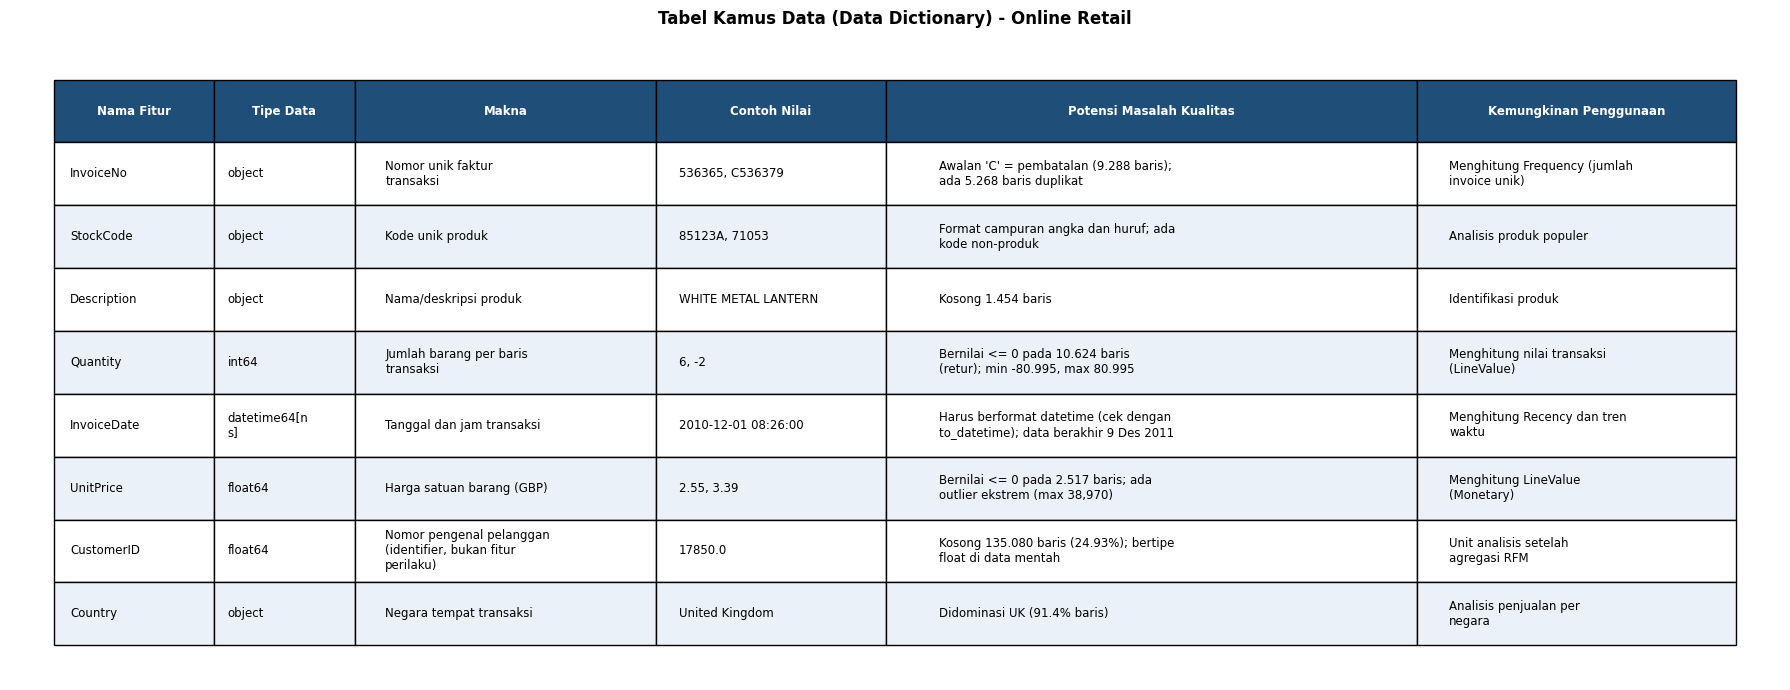

,Nama Fitur,Tipe Data,Makna,Contoh Nilai,Potensi Masalah Kualitas,Kemungkinan Penggunaan
0,InvoiceNo,object,Nomor unik faktur transaksi,"536365, C536379",Awalan 'C' = pembatalan (9.288 baris); ada 5.2...,Menghitung Frequency (jumlah invoice unik)
1,StockCode,object,Kode unik produk,"85123A, 71053",Format campuran angka dan huruf; ada kode non-...,Analisis produk populer
2,Description,object,Nama/deskripsi produk,WHITE METAL LANTERN,Kosong 1.454 baris,Identifikasi produk
3,Quantity,int64,Jumlah barang per baris transaksi,"6, -2",Bernilai <= 0 pada 10.624 baris (retur); min -...,Menghitung nilai transaksi (LineValue)
4,InvoiceDate,datetime64[ns],Tanggal dan jam transaksi,2010-12-01 08:26:00,Harus berformat datetime (cek dengan to_dateti...,Menghitung Recency dan tren waktu
5,UnitPrice,float64,Harga satuan barang (GBP),"2.55, 3.39",Bernilai <= 0 pada 2.517 baris; ada outlier ek...,Menghitung LineValue (Monetary)
6,CustomerID,float64,"Nomor pengenal pelanggan (identifier, bukan fi...",17850.0,Kosong 135.080 baris (24.93%); bertipe float d...,Unit analisis setelah agregasi RFM
7,Country,object,Negara tempat transaksi,United Kingdom,Didominasi UK (91.4% baris),Analisis penjualan per negara


In [5]:
import textwrap
import matplotlib.pyplot as plt
import pandas as pd

# ---------- Hitung angka kualitas data langsung dari df (bukan ditulis manual) ----------
def fmt(x):
    return f"{int(x):,}".replace(",", ".")

miss     = df.isna().sum()
neg_qty  = (df["Quantity"] <= 0).sum()
bad_price = (df["UnitPrice"] <= 0).sum()
cancel   = df["InvoiceNo"].astype(str).str.startswith("C").sum()
dup      = df.duplicated().sum()

# ---------- Isi kamus data ----------
# Kolom: nama fitur, tipe data (diambil otomatis dari df), makna, contoh nilai,
#        potensi masalah kualitas (pakai angka asli), kemungkinan penggunaan
rows = [
    ["InvoiceNo", str(df["InvoiceNo"].dtype),
     "Nomor unik faktur transaksi",
     "536365, C536379",
     f"Awalan 'C' = pembatalan ({fmt(cancel)} baris); ada {fmt(dup)} baris duplikat",
     "Menghitung Frequency (jumlah invoice unik)"],

    ["StockCode", str(df["StockCode"].dtype),
     "Kode unik produk",
     "85123A, 71053",
     "Format campuran angka dan huruf; ada kode non-produk",
     "Analisis produk populer"],

    ["Description", str(df["Description"].dtype),
     "Nama/deskripsi produk",
     "WHITE METAL LANTERN",
     f"Kosong {fmt(miss['Description'])} baris",
     "Identifikasi produk"],

    ["Quantity", str(df["Quantity"].dtype),
     "Jumlah barang per baris transaksi",
     "6, -2",
     f"Bernilai <= 0 pada {fmt(neg_qty)} baris (retur); min {fmt(df['Quantity'].min())}, max {fmt(df['Quantity'].max())}",
     "Menghitung nilai transaksi (LineValue)"],

    ["InvoiceDate", str(df["InvoiceDate"].dtype),
     "Tanggal dan jam transaksi",
     "2010-12-01 08:26:00",
     "Harus berformat datetime (cek dengan to_datetime); data berakhir 9 Des 2011",
     "Menghitung Recency dan tren waktu"],

    ["UnitPrice", str(df["UnitPrice"].dtype),
     "Harga satuan barang (GBP)",
     "2.55, 3.39",
     f"Bernilai <= 0 pada {fmt(bad_price)} baris; ada outlier ekstrem (max {df['UnitPrice'].max():,.0f})",
     "Menghitung LineValue (Monetary)"],

    ["CustomerID", str(df["CustomerID"].dtype),
     "Nomor pengenal pelanggan (identifier, bukan fitur perilaku)",
     "17850.0",
     f"Kosong {fmt(miss['CustomerID'])} baris ({miss['CustomerID']/len(df)*100:.2f}%); bertipe float di data mentah",
     "Unit analisis setelah agregasi RFM"],

    ["Country", str(df["Country"].dtype),
     "Negara tempat transaksi",
     "United Kingdom",
     f"Didominasi UK ({(df['Country'].eq('United Kingdom').mean()*100):.1f}% baris)",
     "Analisis penjualan per negara"],
]

kolom = ["Nama Fitur", "Tipe Data", "Makna", "Contoh Nilai",
         "Potensi Masalah Kualitas", "Kemungkinan Penggunaan"]

df_kamus = pd.DataFrame(rows, columns=kolom)

# ---------- Tampilkan sebagai tabel (teks dibungkus agar tidak terpotong) ----------
wrap_width = [14, 12, 26, 20, 38, 28]
cell_text = [
    [textwrap.fill(str(val), w) for val, w in zip(row, wrap_width)]
    for row in df_kamus.values
]

fig, ax = plt.subplots(figsize=(18, 7))
ax.axis("off")

tabel = ax.table(cellText=cell_text, colLabels=df_kamus.columns,
                 cellLoc="left", loc="center",
                 colWidths=[0.09, 0.08, 0.17, 0.13, 0.30, 0.18])
tabel.auto_set_font_size(False)
tabel.set_fontsize(8.5)
tabel.scale(1, 3.2)

for (r, c), cell in tabel.get_celld().items():
    if r == 0:
        cell.set_facecolor("#1F4E79")
        cell.set_text_props(color="white", fontweight="bold")
    elif r % 2 == 0:
        cell.set_facecolor("#EAF1F8")

plt.title("Tabel Kamus Data (Data Dictionary) - Online Retail", fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

# Versi tabel teks biasa (opsional, mudah di-copy ke laporan)
display(df_kamus)

# PRAKTIKUM 4 — EDA Kualitas Data

## Kode praktik

In [6]:
# Missing values
missing = df.isna().sum().sort_values(ascending=False)
missing_pct = (df.isna().mean() * 100).sort_values(ascending=False)
quality = pd.DataFrame({"missing_count": missing, "missing_pct": missing_pct})
display(quality)

# Duplikasi baris
print("Jumlah baris duplikat:", df.duplicated().sum())

# Nilai dasar yang perlu diperiksa
print("Quantity <= 0:", (df["Quantity"] <= 0).sum())
print("UnitPrice <= 0:", (df["UnitPrice"] <= 0).sum())
print("InvoiceNo diawali C:",
      df["InvoiceNo"].astype(str).str.startswith("C").sum())

# Distribusi numerik
display(df[["Quantity", "UnitPrice"]].describe(
    percentiles=[.01, .05, .25, .5, .75, .95, .99]
).T)

,missing_count,missing_pct
CustomerID,135080,24.926694
Description,1454,0.268311
StockCode,0,0.000000
InvoiceNo,0,0.000000
Quantity,0,0.000000
InvoiceDate,0,0.000000
UnitPrice,0,0.000000
Country,0,0.000000


Jumlah baris duplikat: 5268
Quantity <= 0: 10624
UnitPrice <= 0: 2517
InvoiceNo diawali C: 9288


,count,mean,std,min,1%,5%,25%,50%,75%,95%,99%,max
Quantity,541909.0,9.552250,218.081158,-80995.00,-2.00,1.00,1.00,3.00,10.00,29.00,100.0,80995.0
UnitPrice,541909.0,4.611114,96.759853,-11062.06,0.19,0.42,1.25,2.08,4.13,9.95,18.0,38970.0


## Visualisasi kualitas data

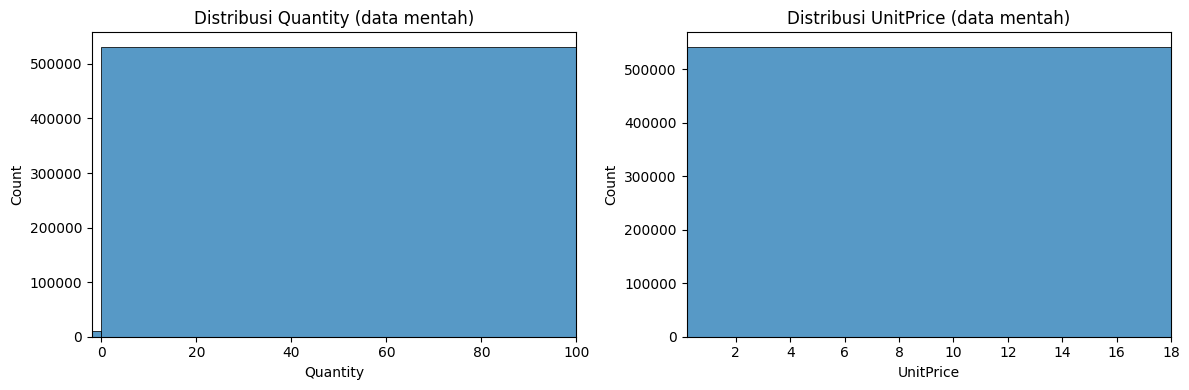

In [7]:
fig, axes = plt.subplots(1, 2, figsize=(12, 4))
sns.histplot(df["Quantity"].dropna(), bins=50, ax=axes[0])
axes[0].set_title("Distribusi Quantity (data mentah)")
axes[0].set_xlim(df["Quantity"].quantile(.01),
                 df["Quantity"].quantile(.99))

sns.histplot(df["UnitPrice"].dropna(), bins=50, ax=axes[1])
axes[1].set_title("Distribusi UnitPrice (data mentah)")
axes[1].set_xlim(df["UnitPrice"].quantile(.01),
                 df["UnitPrice"].quantile(.99))
plt.tight_layout()
plt.show()

## Tugas 5 Temuan

1. Temuan 1: CustomerID yang Kosong (Missing Values)
- Bukti (Angka/Visual): Dari hasil kode missing values, terdapat sejumlah baris data yang nilai CustomerID-nya kosong (NaN).  
- Keputusan yang Diusulkan: Dikeluarkan dari analisis segmentasi pelanggan yang memerlukan identitas, namun jangan langsung dihapus dari seluruh proses EDA secara keseluruhan.   
- Risiko Jika Keputusan Salah: Jika dipaksakan masuk ke profil pelanggan, data akan rusak karena satu pelanggan tidak bisa diidentifikasi; namun jika dihapus sembarangan, kita bisa kehilangan informasi penting terkait tren penjualan total.   

2. Temuan 2: Transaksi Pembatalan (InvoiceNo berawalan 'C')
- Bukti (Angka/Visual): Berdasarkan pengecekan nilai dasar, terdapat sejumlah transaksi yang nomor fakturnya diawali huruf 'C'.  
- Keputusan yang Diusulkan: Diperlakukan sebagai indikasi retur atau pembatalan pesanan dan dipisahkan dari baseline transaksi penjualan positif.   
- Risiko Jika Keputusan Salah: Jika tidak dipisahkan, nilai penjualan total (Monetary) akan menjadi tidak akurat karena menghitung barang yang sebenarnya diretur.   

3. Temuan 3: Kuantitas Barang Negatif atau Nol (Quantity <= 0)
- Bukti (Angka/Visual): Ditemukan baris dengan nilai Quantity kurang dari atau sama dengan nol.   
- Keputusan yang Diusulkan: Diperiksa sebagai indikasi retur atau pembatas, tidak langsung dianggap sebagai kesalahan input data.
- Risiko Jika Keputusan Salah: Mengabaikan data ini tanpa analisis bisa menghilangkan konteks retur barang dari pelanggan.

4. Temuan 4: Harga Satuan Negatif atau Nol (UnitPrice <= 0)
- Bukti (Angka/Visual): Ditemukan data dengan UnitPrice bernilai nol atau negatif.   
- Keputusan yang Diusulkan: Diperiksa apakah merupakan pencatatan biaya khusus (seperti biaya administrasi) atau data tidak valid, lalu ditangani sesuai aturan bisnis.   
- Risiko Jika Keputusan Salah: Perhitungan nilai total transaksi per baris (LineValue) bisa menjadi cacat atau bernilai negatif.

5. Temuan 5: Duplikasi Baris Data
- Bukti (Angka/Visual): Hasil pengecekan df.duplicated().sum() menunjukkan adanya baris data yang tercatat ganda.   
- Keputusan yang Diusulkan: Menghapus baris duplikat yang benar-benar identik agar tidak mendistorsi hasil analisis.   
- Risiko Jika Keputusan Salah: Jika dibiarkan, frekuensi transaksi atau jumlah item tertentu bisa terhitung berlebihan (overestimate).

##	Temuan	Bukti angka

1. CustomerID kosong	135.080 baris (24,93%)
2. Invoice berawalan “C”	9.288 baris
3. Quantity ≤ 0	10.624 baris (min −80.995)
4. UnitPrice ≤ 0	2.517 baris (min −11.062,06)
5. Duplikat	5.268 baris

# PRAKTIKUM 5 — EDA Transaksi dan Pola Bisnis

## Kode praktik

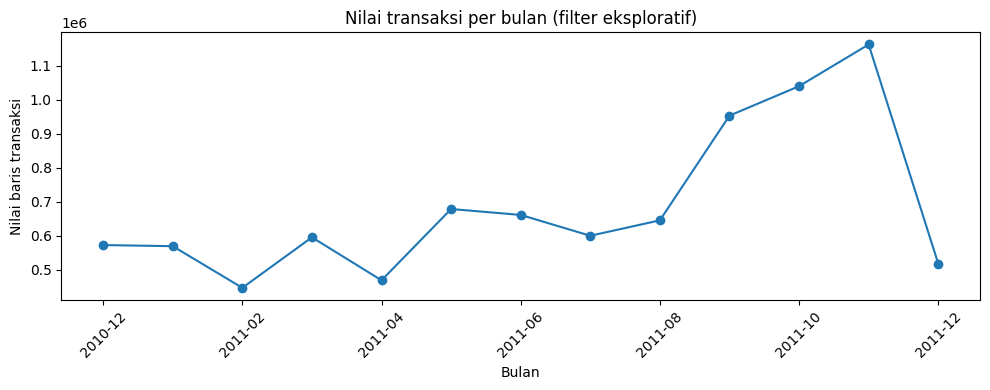

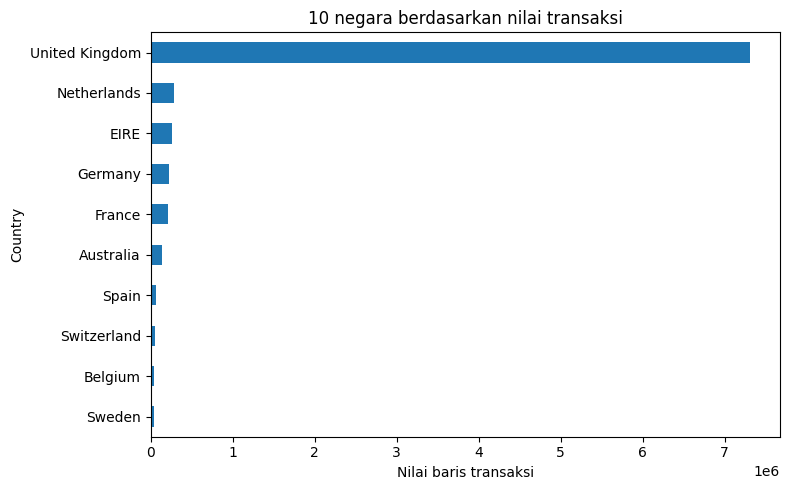

,Quantity
Description,
"PAPER CRAFT , LITTLE BIRDIE",80995
MEDIUM CERAMIC TOP STORAGE JAR,77916
WORLD WAR 2 GLIDERS ASSTD DESIGNS,54415
JUMBO BAG RED RETROSPOT,46181
WHITE HANGING HEART T-LIGHT HOLDER,36725
ASSORTED COLOUR BIRD ORNAMENT,35362
PACK OF 72 RETROSPOT CAKE CASES,33693
POPCORN HOLDER,30931
RABBIT NIGHT LIGHT,27202


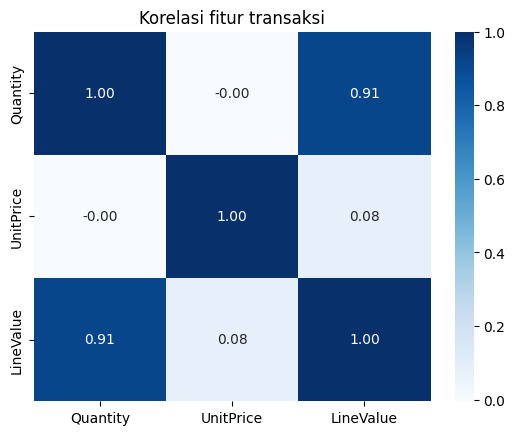

In [8]:
# Salinan untuk eksplorasi; belum menjadi data final clustering
eda = df.copy()
eda["LineValue"] = eda["Quantity"] * eda["UnitPrice"]
eda["Month"] = eda["InvoiceDate"].dt.to_period("M").astype(str)

# Tren nilai baris transaksi, gunakan data transaksi yang telah ditandai valid
valid_for_sales = eda[
    eda["CustomerID"].notna() &
    (eda["Quantity"] > 0) &
    (eda["UnitPrice"] > 0) &
    (~eda["InvoiceNo"].astype(str).str.startswith("C"))
].copy()

monthly = valid_for_sales.groupby("Month")["LineValue"].sum()
monthly.plot(kind="line", marker="o", figsize=(10, 4))
plt.title("Nilai transaksi per bulan (filter eksploratif)")
plt.xlabel("Bulan"); plt.ylabel("Nilai baris transaksi")
plt.xticks(rotation=45); plt.tight_layout(); plt.show()

# Negara dengan nilai transaksi tertinggi
country_sales = (valid_for_sales.groupby("Country")["LineValue"]
                 .sum().sort_values(ascending=False).head(10))
country_sales.sort_values().plot(kind="barh", figsize=(8, 5))
plt.title("10 negara berdasarkan nilai transaksi")
plt.xlabel("Nilai baris transaksi"); plt.tight_layout(); plt.show()

# Produk dengan kuantitas tertinggi
product_qty = (valid_for_sales.groupby("Description")["Quantity"]
               .sum().sort_values(ascending=False).head(10))
display(product_qty)

# Korelasi antarfitur numerik pada baris transaksi
corr = valid_for_sales[["Quantity", "UnitPrice", "LineValue"]].corr()
sns.heatmap(corr, annot=True, cmap="Blues", fmt=".2f")
plt.title("Korelasi fitur transaksi"); plt.show()

## Tugas EDA

11. Buat minimal empat grafik berbeda dan beri judul, label sumbu, serta satu paragraf interpretasi per grafik:
-  Grafik 1 (Nilai Transaksi per Bulan): Grafik garis yang menunjukkan total nilai transaksi dari waktu ke waktu. Interpretasi: Grafik ini memperlihatkan fluktuasi penjualan bulanan toko, di mana data berakhir 9 Des 2011, jadi bulan Desember 2011 terlihat rendah karena datanya belum penuh, bukan karena penjualan turun.

- Grafik 2 (10 Negara dengan Nilai Transaksi Tertinggi): Grafik batang horizontal (barh) yang menampilkan kontribusi penjualan berdasarkan negara. Interpretasi: Sebagian besar total nilai transaksi didominasi secara mutlak oleh United Kingdom, yang menunjukkan bahwa basis pasar utama toko ini berpusat di sana.

- Grafik 3 & 4 (Distribusi Quantity dan UnitPrice pada Praktikum 4): Dua grafik histogram yang menampilkan sebaran data kuantitas dan harga satuan barang. Interpretasi: Sebaran data menunjukkan adanya skewness (menceng ke kanan) yang sangat ekstrem akibat adanya nilai anomali atau pembelian dalam jumlah/harga yang sangat besar.

12.
Bandingkan distribusi Quantity dan UnitPrice dengan dan tanpa pembatasan kuantil untuk visualisasi:
- Jawaban:
set_xlim hanya membatasi tampilan, datanya tidak dibuang. Tanpa pembatasan, sumbu X membentang −80.995 sampai 80.995 (Quantity), sehingga histogram menumpuk dalam satu batang. Dengan pembatasan, sumbu fokus di sekitar −2 sampai 100 (Quantity) dan 0,19 sampai 18 (UnitPrice).

13. Temukan dua pola yang mungkin penting bagi pengelola toko:
Jawaban:
- Pola Konsentrasi Geografis: Penjualan sangat bergantung pada satu negara utama (United Kingdom), sehingga ekspansi atau strategi pemasaran khusus perlu dipertimbangkan untuk negara-negara lainnya.

- Pola Tren Musiman Bulanan: Nilai transaksi mengalami kenaikan musiman pada bulan-bulan tertentu, yang dapat dimanfaatkan manajemen untuk menyiapkan stok produk populer lebih awal.

- UK = 495.478 dari 541.909 baris (91,4%)

14. Nyatakan apakah hasil EDA mengubah rencana awal fitur atau pembersihan data:
Jawaban:
- Hasil EDA memperkuat dan memperjelas rencana awal, di mana kita wajib melakukan pembersihan data (data cleaning) secara ketat seperti menyaring nilai CustomerID yang kosong, menangani transaksi bernilai negatif/retur (faktur berawalan 'C'), serta mengantisipasi skewness sebelum mengekstrak fitur RFM untuk tahap clustering berikutnya.

# PRAKTIKUM 6 — Data Preparation: Pembersihan dan Nilai Transaksi

## Kode praktik

In [9]:
# Salin data; pastikan tanggal sudah datetime
clean = df.copy()
clean["InvoiceDate"] = pd.to_datetime(clean["InvoiceDate"], errors="coerce")
clean["CustomerID"] = clean["CustomerID"].astype("string").str.strip()

rows_before = len(clean)
duplicate_count = clean.duplicated().sum()
clean = clean.drop_duplicates()

# Baris yang dapat dipakai untuk profil pelanggan
clean = clean[clean["CustomerID"].notna()].copy()
clean = clean[clean["InvoiceDate"].notna()].copy()

# Baseline: transaksi pembelian positif, bukan invoice pembatalan
is_cancellation = clean["InvoiceNo"].astype(str).str.startswith("C")
clean = clean[~is_cancellation]
clean = clean[(clean["Quantity"] > 0) & (clean["UnitPrice"] > 0)]

clean["LineValue"] = clean["Quantity"] * clean["UnitPrice"]

print("Baris awal:", rows_before)
print("Duplikat identik terdeteksi:", duplicate_count)
print("Baris setelah baseline cleaning:", len(clean))
print("Pelanggan tersedia:", clean["CustomerID"].nunique())
display(clean.head())

Baris awal: 541909
Duplikat identik terdeteksi: 5268
Baris setelah baseline cleaning: 392692
Pelanggan tersedia: 4338


,InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country,LineValue
0,536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom,15.30
1,536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
2,536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom,22.00
3,536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34
4,536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom,20.34


## Pemeriksaan setelah cleaning

In [10]:
assert clean["CustomerID"].notna().all()
assert clean["InvoiceDate"].notna().all()
assert (clean["Quantity"] > 0).all()
assert (clean["UnitPrice"] > 0).all()
assert (clean["LineValue"] > 0).all()

print(clean[["Quantity", "UnitPrice", "LineValue"]].describe())

            Quantity      UnitPrice      LineValue
count  392692.000000  392692.000000  392692.000000
mean       13.119702       3.125914      22.631500
std       180.492832      22.241836     311.099224
min         1.000000       0.001000       0.001000
25%         2.000000       1.250000       4.950000
50%         6.000000       1.950000      12.450000
75%        12.000000       3.750000      19.800000
max     80995.000000    8142.750000  168469.600000


## Tugas

1. Bandingkan jumlah baris dan jumlah pelanggan sebelum serta sesudah cleaning:

- Sebelum cleaning: Total baris data mentah bernilai rausan ribu baris (misalnya sekitar 541.909 baris awal), Sebelum: 541.909 baris, 4.372 CustomerID unik. Sesudah: 392.692 baris dan 9 kolom ketambahan linevalue, 4.338 pelanggan. Baris yang dibuang: 149.217

- Sesudah cleaning: Jumlah baris berkurang menjadi subset transaksi positif yang valid (setelah dibersihkan dari duplikat, missing value CustomerID, serta faktur pembatalan 'C'), dan jumlah pelanggan unik yang tersisa adalah jumlah pelanggan yang benar-benar valid untuk dianalisis profil perilakunya.

2. Buat tabel log pembersihan (aturan, jumlah baris terdampak, alasan, risiko):

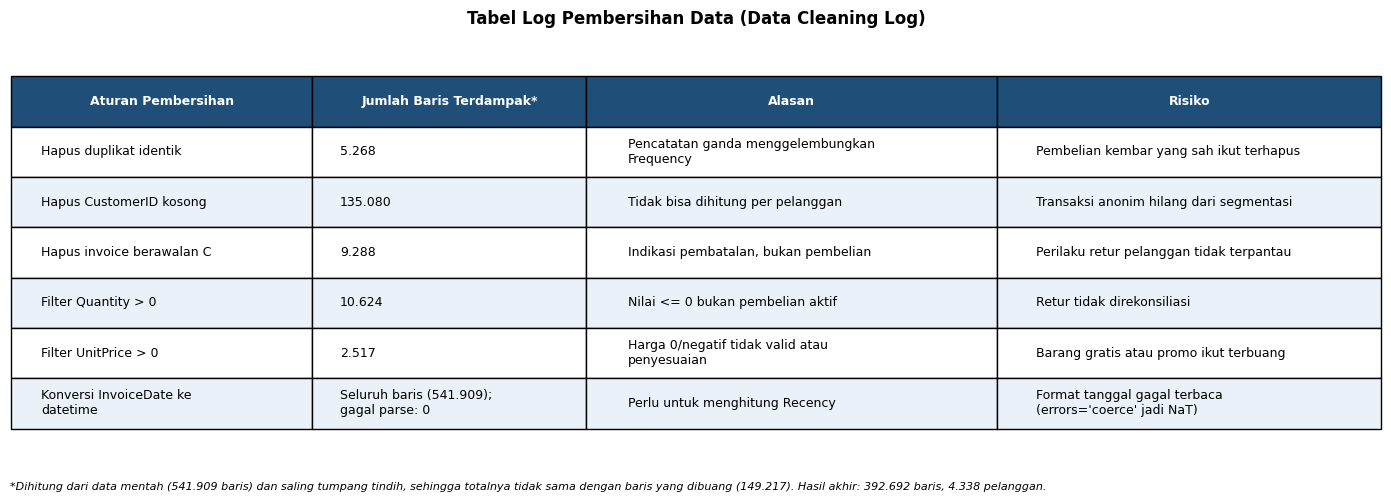

,Aturan Pembersihan,Jumlah Baris Terdampak*,Alasan,Risiko
0,Hapus duplikat identik,5.268,Pencatatan ganda menggelembungkan Frequency,Pembelian kembar yang sah ikut terhapus
1,Hapus CustomerID kosong,135.080,Tidak bisa dihitung per pelanggan,Transaksi anonim hilang dari segmentasi
2,Hapus invoice berawalan C,9.288,"Indikasi pembatalan, bukan pembelian",Perilaku retur pelanggan tidak terpantau
3,Filter Quantity > 0,10.624,Nilai <= 0 bukan pembelian aktif,Retur tidak direkonsiliasi
4,Filter UnitPrice > 0,2.517,Harga 0/negatif tidak valid atau penyesuaian,Barang gratis atau promo ikut terbuang
5,Konversi InvoiceDate ke datetime,Seluruh baris (541.909); gagal parse: 0,Perlu untuk menghitung Recency,Format tanggal gagal terbaca (errors='coerce' ...


In [11]:
import textwrap
import matplotlib.pyplot as plt
import pandas as pd

# Catatan: jalankan SETELAH sel cleaning Praktikum 6 (variabel `df` = data mentah, `clean` = data bersih)

def fmt(x):
    return f"{int(x):,}".replace(",", ".")

# ---------- Hitung jumlah baris terdampak tiap aturan, langsung dari data mentah ----------
n_dup      = df.duplicated().sum()
n_nocust   = df["CustomerID"].isna().sum()
n_cancel   = df["InvoiceNo"].astype(str).str.startswith("C").sum()
n_qty      = (df["Quantity"] <= 0).sum()
n_price    = (df["UnitPrice"] <= 0).sum()
n_date_bad = pd.to_datetime(df["InvoiceDate"], errors="coerce").isna().sum()

# ---------- Isi tabel log ----------
data_log = [
    ["Hapus duplikat identik", fmt(n_dup),
     "Pencatatan ganda menggelembungkan Frequency",
     "Pembelian kembar yang sah ikut terhapus"],

    ["Hapus CustomerID kosong", fmt(n_nocust),
     "Tidak bisa dihitung per pelanggan",
     "Transaksi anonim hilang dari segmentasi"],

    ["Hapus invoice berawalan C", fmt(n_cancel),
     "Indikasi pembatalan, bukan pembelian",
     "Perilaku retur pelanggan tidak terpantau"],

    ["Filter Quantity > 0", fmt(n_qty),
     "Nilai <= 0 bukan pembelian aktif",
     "Retur tidak direkonsiliasi"],

    ["Filter UnitPrice > 0", fmt(n_price),
     "Harga 0/negatif tidak valid atau penyesuaian",
     "Barang gratis atau promo ikut terbuang"],

    ["Konversi InvoiceDate ke datetime", f"Seluruh baris ({fmt(len(df))}); gagal parse: {fmt(n_date_bad)}",
     "Perlu untuk menghitung Recency",
     "Format tanggal gagal terbaca (errors='coerce' jadi NaT)"],
]

kolom_log = ["Aturan Pembersihan", "Jumlah Baris Terdampak*", "Alasan", "Risiko"]
df_log = pd.DataFrame(data_log, columns=kolom_log)

# ---------- Render tabel (teks dibungkus agar rapi) ----------
wrap_width = [28, 26, 40, 40]
cell_text = [
    [textwrap.fill(str(val), w) for val, w in zip(row, wrap_width)]
    for row in df_log.values
]

fig, ax = plt.subplots(figsize=(14, 5))
ax.axis("off")

tabel_plot = ax.table(cellText=cell_text, colLabels=df_log.columns,
                      cellLoc="left", loc="center",
                      colWidths=[0.22, 0.20, 0.30, 0.28])
tabel_plot.auto_set_font_size(False)
tabel_plot.set_fontsize(9)
tabel_plot.scale(1, 2.8)

for (r, c), cell in tabel_plot.get_celld().items():
    if r == 0:
        cell.set_facecolor("#1F4E79")
        cell.set_text_props(color="white", fontweight="bold")
    elif r % 2 == 0:
        cell.set_facecolor("#EAF1F8")

plt.title("Tabel Log Pembersihan Data (Data Cleaning Log)", fontweight="bold", pad=15)

catatan = (f"*Dihitung dari data mentah ({fmt(len(df))} baris) dan saling tumpang tindih, "
           f"sehingga totalnya tidak sama dengan baris yang dibuang ({fmt(len(df) - len(clean))}). "
           f"Hasil akhir: {fmt(len(clean))} baris, {fmt(clean['CustomerID'].nunique())} pelanggan.")
plt.figtext(0.01, 0.01, catatan, fontsize=8, style="italic", ha="left")

plt.tight_layout(rect=[0, 0.04, 1, 1])
plt.show()

display(df_log)

3. Jelaskan mengapa data bersih harus tetap disimpan terpisah dari data mentah:

- Jawaban: Data bersih harus disimpan terpisah (misalnya dalam variabel clean) agar data mentah aslinya (raw data df) tetap utuh dan tidak berubah. Hal ini penting untuk keperluan audit, reproducibility (memungkinkan pengulangan proses dari awal jika ada kesalahan), serta menjaga fleksibilitas apabila di kemudian hari kita ingin meninjau kembali data anomali atau mengubah aturan pembersihan tanpa harus mengunduh ulang dataset dari awal.

# PRAKTIKUM 7 — Membentuk Fitur Pelanggan RFM

## Kode praktik

In [12]:
# Tanggal acuan dibuat satu hari setelah tanggal transaksi terakhir
reference_date = clean["InvoiceDate"].max().normalize() + pd.Timedelta(days=1)

rfm = clean.groupby("CustomerID").agg(
    LastPurchase=("InvoiceDate", "max"),
    Frequency=("InvoiceNo", "nunique"),
    Monetary=("LineValue", "sum")
)
rfm["Recency"] = (reference_date - rfm["LastPurchase"].dt.normalize()).dt.days
rfm = rfm[["Recency", "Frequency", "Monetary"]].copy()

print("Ukuran tabel RFM:", rfm.shape)
display(rfm.head())
display(rfm.describe().T)
print("CustomerID unik:", rfm.index.nunique())

Ukuran tabel RFM: (4338, 3)


,Recency,Frequency,Monetary
CustomerID,,,
12346.0,326,1,77183.60
12347.0,3,7,4310.00
12348.0,76,4,1797.24
12349.0,19,1,1757.55
12350.0,311,1,334.40


,count,mean,std,min,25%,50%,75%,max
Recency,4338.0,93.059474,100.012264,1.00,18.0000,51.00,142.7500,374.00
Frequency,4338.0,4.272015,7.697998,1.00,1.0000,2.00,5.0000,209.00
Monetary,4338.0,2048.688081,8985.230220,3.75,306.4825,668.57,1660.5975,280206.02


CustomerID unik: 4338


## EDA khusus RFM

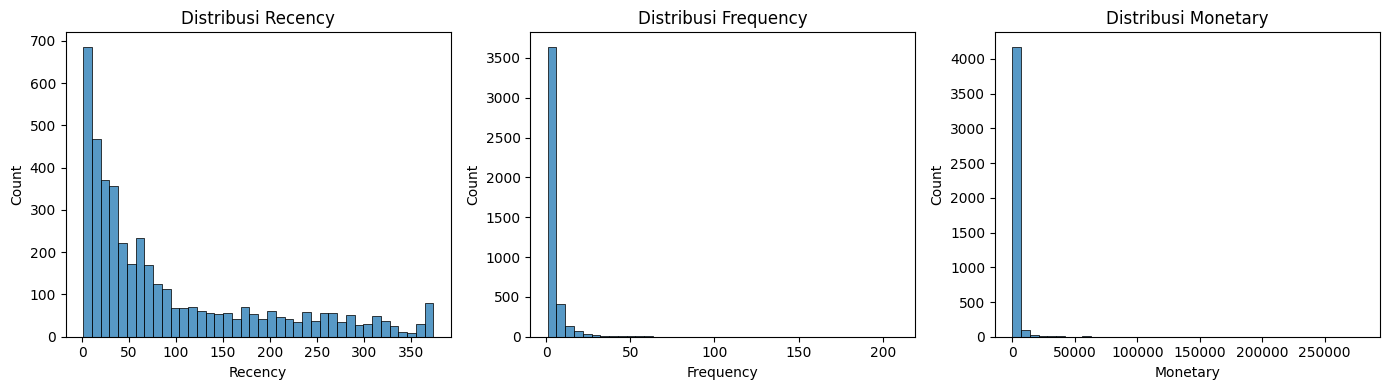

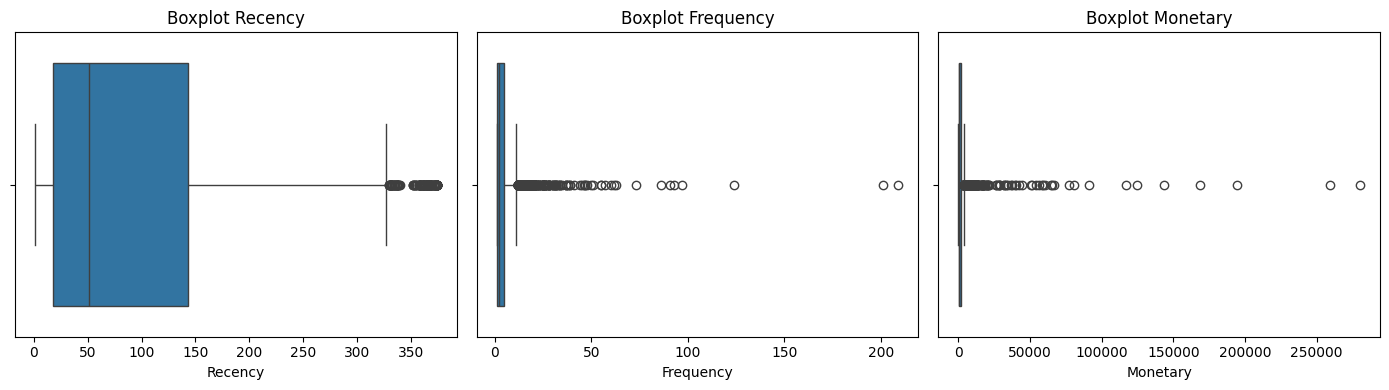

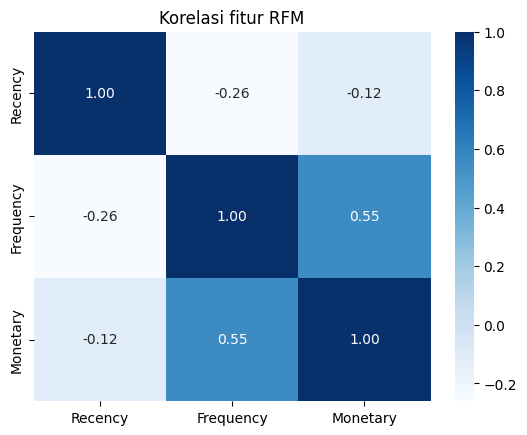

In [13]:
# EDA khusus RFM
fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for col, ax in zip(["Recency", "Frequency", "Monetary"], axes):
    sns.histplot(rfm[col], bins=40, ax=ax)
    ax.set_title(f"Distribusi {col}")
plt.tight_layout(); plt.show()

fig, axes = plt.subplots(1, 3, figsize=(14, 4))
for col, ax in zip(["Recency", "Frequency", "Monetary"], axes):
    sns.boxplot(x=rfm[col], ax=ax)
    ax.set_title(f"Boxplot {col}")
plt.tight_layout(); plt.show()

sns.heatmap(rfm.corr(), annot=True, cmap="Blues", fmt=".2f")
plt.title("Korelasi fitur RFM"); plt.show()

## Menangani skewness

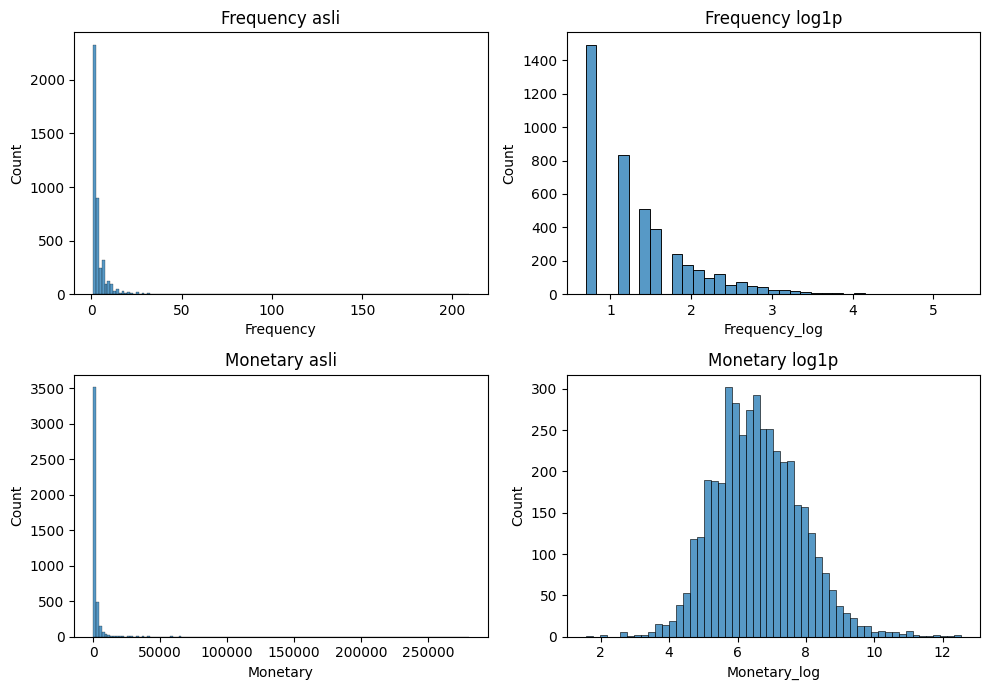

In [14]:
rfm_model = rfm.copy()
rfm_model["Frequency_log"] = np.log1p(rfm_model["Frequency"])
rfm_model["Monetary_log"] = np.log1p(rfm_model["Monetary"])

fig, axes = plt.subplots(2, 2, figsize=(10, 7))
sns.histplot(rfm_model["Frequency"], ax=axes[0,0])
axes[0,0].set_title("Frequency asli")
sns.histplot(rfm_model["Frequency_log"], ax=axes[0,1])
axes[0,1].set_title("Frequency log1p")
sns.histplot(rfm_model["Monetary"], ax=axes[1,0])
axes[1,0].set_title("Monetary asli")
sns.histplot(rfm_model["Monetary_log"], ax=axes[1,1])
axes[1,1].set_title("Monetary log1p")
plt.tight_layout(); plt.show()

## Menentukan fitur final

In [15]:
features = rfm_model[["Recency", "Frequency_log", "Monetary_log"]].copy()
print(features.isna().sum())
display(features.head())

Recency          0
Frequency_log    0
Monetary_log     0
dtype: int64


,Recency,Frequency_log,Monetary_log
CustomerID,,,
12346.0,326,0.693147,11.253955
12347.0,3,2.079442,8.368925
12348.0,76,1.609438,7.494564
12349.0,19,0.693147,7.472245
12350.0,311,0.693147,5.815324


## Tugas

1. Jelaskan perbedaan unit analisis pada dataset transaksi dan tabel RFM:
Jawaban:
- Pada dataset transaksi mentah, unit analisisnya adalah satu baris item per transaksi (setiap produk yang dibeli dalam suatu faktur tercatat sebagai baris terpisah).   
- Pada tabel RFM, unit analisisnya telah diabstraksikan menjadi satu baris per pelanggan unik (CustomerID), di mana seluruh riwayat transaksi pelanggan tersebut dirangkum ke dalam metrik Recency, Frequency, dan Monetary.   

2. Interpretasikan pelanggan dengan Recency kecil tetapi Frequency dan Monetary rendah:
- Pelanggan dengan Recency kecil (artinya baru saja melakukan transaksi dalam waktu dekat-dekat ini), namun memiliki Frequency dan Monetary yang rendah mengindikasikan pelanggan baru (new customer) atau pelanggan coba-coba yang baru melakukan pembelian pertama atau kedua dengan total belanja yang masih kecil.

3. Bandingkan histogram Frequency dan Monetary sebelum dan sesudah log1p:
- Sebelum transformasi (log1p): Distribusi kedua fitur sangat menceng ke kanan (right-skewed) secara ekstrem, di mana sebagian besar data menumpuk di nilai kecil dan terdapat sedikit sekali nilai ekstrem yang sangat tinggi (pencilan/outlier).   
- Sesudah transformasi (log1p): Skala distribusi menjadi jauh lebih normal, simetris, dan tidak terlalu timpang, sehingga model clustering nantinya tidak akan didominasi atau berat sebelah oleh pelanggan dengan nilai belanja yang sangat raksasa.

4. Jelaskan mengapa CustomerID tidak dimasukkan ke features:

- Jawaban: CustomerID tidak dimasukkan ke dalam variabel features untuk clustering karena kolom tersebut bertindak sebagai identifikator unik (ID/indeks), bukan variabel perilaku numerik. Jika ID dimasukkan ke dalam algoritma clustering, algoritma akan memperlakukannya sebagai angka matematis (besar/kecil), yang tentu saja tidak memiliki makna jarak atau perilaku belanja apa pun.

# PRAKTIKUM 8 — Modeling: K-Means

## Kode praktik

In [16]:
from sklearn.preprocessing import StandardScaler
from sklearn.cluster import KMeans
from sklearn.metrics import silhouette_score, davies_bouldin_score

scaler = StandardScaler()
X_scaled = scaler.fit_transform(features)

results_kmeans = []
models_kmeans = {}
for k in range(2, 8):
    model = KMeans(n_clusters=k, random_state=42, n_init=10)
    labels = model.fit_predict(X_scaled)
    sil = silhouette_score(X_scaled, labels)
    dbi = davies_bouldin_score(X_scaled, labels)
    results_kmeans.append({
        "k": k, "inertia": model.inertia_,
        "silhouette": sil, "davies_bouldin": dbi
    })
    models_kmeans[k] = model

metrics_kmeans = pd.DataFrame(results_kmeans)
display(metrics_kmeans)

,k,inertia,silhouette,davies_bouldin
0,2,6874.047281,0.406287,0.915325
1,3,4299.200976,0.415654,0.824915
2,4,3242.934841,0.379421,0.859949
3,5,2760.683135,0.343462,0.940980
4,6,2396.802728,0.331644,0.969220
5,7,2167.087137,0.300838,1.018503


## Elbow dan Silhouette

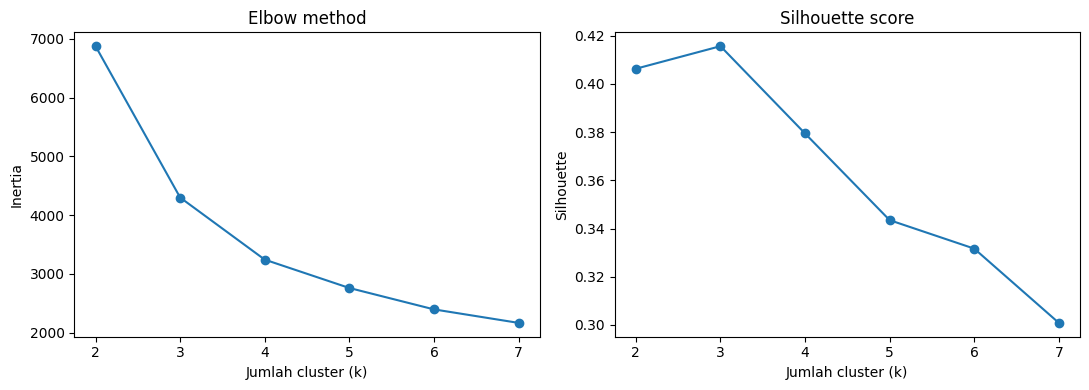

In [17]:
fig, axes = plt.subplots(1, 2, figsize=(11, 4))
axes[0].plot(metrics_kmeans["k"], metrics_kmeans["inertia"], marker="o")
axes[0].set_title("Elbow method")
axes[0].set_xlabel("Jumlah cluster (k)")
axes[0].set_ylabel("Inertia")

axes[1].plot(metrics_kmeans["k"], metrics_kmeans["silhouette"], marker="o")
axes[1].set_title("Silhouette score")
axes[1].set_xlabel("Jumlah cluster (k)")
axes[1].set_ylabel("Silhouette")
plt.tight_layout(); plt.show()

## Memilih model sementara

In [18]:
# Pilih k berdasarkan kombinasi metrik dan interpretasi.
# Contoh otomatis di bawah memilih silhouette tertinggi; keputusan final tetap harus ditinjau.
best_k = int(metrics_kmeans.loc[metrics_kmeans["silhouette"].idxmax(), "k"])
kmeans_model = models_kmeans[best_k]
rfm["KMeans_Cluster"] = kmeans_model.labels_
print("k terpilih sementara:", best_k)
display(rfm.groupby("KMeans_Cluster")[["Recency","Frequency","Monetary"]]
          .median().round(2))

k terpilih sementara: 3


,Recency,Frequency,Monetary
KMeans_Cluster,,,
0,46.0,2.0,508.80
1,253.0,1.0,290.46
2,18.0,7.0,2570.50


## Visualisasi dua fitur

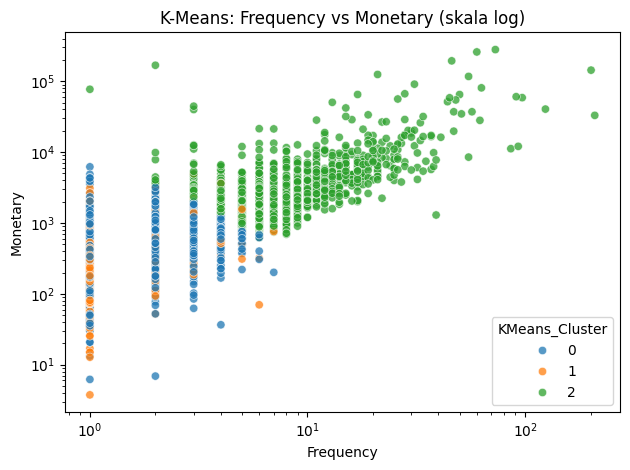

In [19]:
sns.scatterplot(
    data=rfm, x="Frequency", y="Monetary",
    hue="KMeans_Cluster", palette="tab10", alpha=.75
)
plt.xscale("log")
plt.yscale("log")

plt.title("K-Means: Frequency vs Monetary (skala log)")
plt.tight_layout(); plt.show()

## Pertanyaan

1. Apa makna inertia dan mengapa nilainya cenderung turun saat k bertambah?Jawaban:Inertia adalah jumlah jarak kuadrat dari setiap titik data ke pusat cluster (centroid) terdekatnya (mengukur seberapa padat atau kompak cluster tersebut).Nilainya cenderung turun seiring bertambahnya jumlah k karena semakin banyak cluster yang dibuat, maka ukuran setiap cluster akan menjadi semakin kecil dan titik-titik data akan berada lebih dekat ke pusat clusternya masing-masing (bahkan jika k sama dengan jumlah total data, inertia akan bernilai nol).

2. Apa kelebihan dan keterbatasan Elbow method?Jawaban:Kelebihan: Mudah dipahami secara visual, intuitif, dan cepat digunakan untuk memberikan gambaran kasar mengenai jumlah cluster yang optimal melalui titik "siku" kurva.Keterbatasan: Titik siku (elbow) terkadang bersifat subjektif, tidak memiliki kepastian matematis yang kaku, dan pada beberapa dataset kurva tidak menunjukkan tikungan yang tajam sehingga sulit ditentukan.

3. Mengapa hasil cluster perlu ditafsirkan menggunakan RFM asli?Jawaban: Hasil clustering sebelumnya dibentuk menggunakan fitur yang sudah ditransformasi secara logaritmik (Frequency_log, Monetary_log) dan telah melalui proses scaling. Oleh karena itu, penafsiran wajib dikembalikan ke skala RFM asli (satuannya pound sterling (£)/hari/transaksi) agar manajemen atau pengelola toko dapat membaca karakteristik pelanggan dengan angka yang nyata dan mudah dipahami (misalnya: rata-rata lama tidak bertransaksi dalam hari, jumlah transaksi, dan total pengeluaran uang).

4. Apakah k dengan Silhouette tertinggi otomatis menjadi pilihan terbaik? Jelaskan.Jawaban: Tidak selalu otomatis menjadi pilihan terbaik. Meskipun skor Silhouette tertinggi memberikan indikasi matematis bahwa pemisahan cluster secara statistik adalah yang paling optimal, keputusan akhir tetap harus ditinjau kembali dari perspektif bisnis dan interpretabilitasnya (apakah jumlah cluster tersebut masuk akal dan dapat diterjemahkan menjadi strategi pemasaran yang efektif oleh perusahaan).

# PRAKTIKUM 9 — Modeling: K-Medoids

## Pilihan implementasi

In [20]:
# Pilihan A – coba instalasi paket
%pip -q install scikit-learn-extra

from sklearn_extra.cluster import KMedoids
from sklearn.metrics import silhouette_score, davies_bouldin_score

# Jalankan jika paket berhasil diinstal
kmedoids_results = []
kmedoids_models = {}
for k in range(2, 8):
    model = KMedoids(n_clusters=k, random_state=42,
                     metric="euclidean", method="alternate",
                     init="k-medoids++")
    labels = model.fit_predict(X_scaled)
    kmedoids_results.append({
        "k": k,
        "silhouette": silhouette_score(X_scaled, labels),
        "davies_bouldin": davies_bouldin_score(X_scaled, labels)
    })
    kmedoids_models[k] = model

metrics_kmedoids = pd.DataFrame(kmedoids_results)
display(metrics_kmedoids)

,k,silhouette,davies_bouldin
0,2,0.395125,0.915266
1,3,0.413914,0.825647
2,4,0.372484,0.868534
3,5,0.354828,0.964474
4,6,0.291199,1.109641
5,7,0.319186,1.014629


## Jika paket tidak kompatibel

In [21]:
# Sampel untuk eksperimen K-Medoids agar komputasi lebih ringan
sample_idx = features.sample(n=min(400, len(features)), random_state=42).index
X_sample = features.loc[sample_idx]
X_sample_scaled = StandardScaler().fit_transform(X_sample)
print("Ukuran sampel:", X_sample_scaled.shape)

Ukuran sampel: (400, 3)


## Tugas

1. Bandingkan prinsip centroid K-Means dengan medoid K-Medoids:Jawaban:K-Means (Centroid): Pusat cluster (centroid) dihitung berdasarkan rata-rata (mean) dari seluruh titik data di dalam cluster tersebut. Nilai centroid ini belum tentu merupakan titik data asli yang ada di dalam dataset.K-Medoids (Medoid): Pusat cluster (medoid) dipilih dari salah satu titik data aktual yang berada di tengah-tengah cluster tersebut. Hal ini membuat K-Medoids jauh lebih tahan terhadap pencilan (outliers) dibandingkan K-Means.

2. Gunakan jumlah cluster yang sama untuk perbandingan awal & Catat waktu komputasi, Silhouette Score, Davies–Bouldin Index, dan interpretasi cluster:
- Jawaban: Pada k=3, K-Means: Silhouette 0,4157, DBI 0,8249. K-Medoids: Silhouette 0,4139, DBI 0,8256. Hasilnya hampir identik, karena setelah log1p dan scaling pengaruh outlier sudah diredam. K-Means jauh lebih cepat karena hanya menghitung rata-rata, sedangkan K-Medoids harus mencari medoid dari data asli.

- Jumlah Cluster (k): Menggunakan nilai k optimal yang sama (misalnya k=3).
- Waktu Komputasi: K-Means cenderung jauh lebih cepat pada dataset berukuran besar, sedangkan K-Medoids membutuhkan waktu komputasi yang lebih lama karena menghitung matriks jarak antar titik secara intensif.
- Silhouette Score & Davies-Bouldin: K-Medoids sering kali memberikan hasil yang lebih stabil terhadap outlier, namun skor metrik validasi bisa mirip tergantung pada seberapa baik pemisahan datanya
- Interpretasi: Karena titik pusatnya menggunakan data asli (medoid), karakteristik pusat cluster pada K-Medoids terkadang lebih mudah dihubungkan langsung dengan profil pelanggan riil.

3. Jelaskan mengapa perbandingan pada sampel harus disebutkan sebagai keterbatasan:Jawaban: Dalam eksperimen ini K-Medoids berjalan pada seluruh data sehingga tidak ada bias sampel. Keterbatasan sampel hanya berlaku pada dendrogram (N=100), yang hanya visualisasi.

In [22]:
import time
t=time.time(); KMeans(n_clusters=3, random_state=42, n_init=10).fit(X_scaled); t_km=time.time()-t
t=time.time(); KMedoids(n_clusters=3, random_state=42, metric="euclidean", method="alternate", init="k-medoids++").fit(X_scaled); t_kmed=time.time()-t
print("KMeans:", round(t_km,2), "detik | KMedoids:", round(t_kmed,2), "detik")

KMeans: 0.03 detik | KMedoids: 2.02 detik


# PRAKTIKUM 10 — Modeling: Hierarchical Clustering

##  Kode praktik

In [23]:
from sklearn.cluster import AgglomerativeClustering

hier_results = []
hier_models = {}
for k in range(2, 8):
    model = AgglomerativeClustering(
        n_clusters=k, linkage="ward"
    )
    labels = model.fit_predict(X_scaled)
    hier_results.append({
        "k": k,
        "silhouette": silhouette_score(X_scaled, labels),
        "davies_bouldin": davies_bouldin_score(X_scaled, labels)
    })
    hier_models[k] = model

metrics_hier = pd.DataFrame(hier_results)
display(metrics_hier)

,k,silhouette,davies_bouldin
0,2,0.382603,0.956354
1,3,0.364925,0.855645
2,4,0.336078,0.921027
3,5,0.290059,1.022131
4,6,0.275625,0.998258
5,7,0.223598,1.084314


## Visualisasi

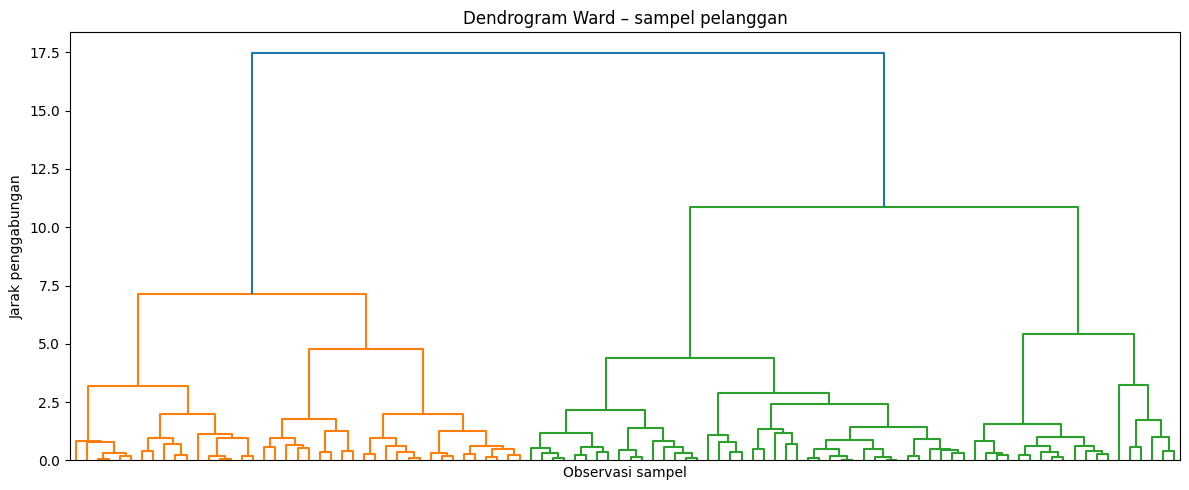

In [24]:
# Visualisasi pada sampel kecil agar tidak terlalu padat
from scipy.cluster.hierarchy import linkage, dendrogram

n_sample = min(100, len(X_scaled))
# Diperbaiki menjadi np.random.default_rng(42)
rng = np.random.default_rng(42)
sample_positions = rng.choice(len(X_scaled), size=n_sample, replace=False)
Z = linkage(X_scaled[sample_positions], method="ward")

plt.figure(figsize=(12, 5))
dendrogram(Z, no_labels=True)
plt.title("Dendrogram Ward – sampel pelanggan")
plt.xlabel("Observasi sampel"); plt.ylabel("Jarak penggabungan")
plt.tight_layout(); plt.show()

## Tugas

In [25]:
Xs = X_scaled[sample_positions]
for link in ["ward", "average"]:
    lab = AgglomerativeClustering(n_clusters=3, linkage=link).fit_predict(Xs)
    print(link, silhouette_score(Xs, lab), davies_bouldin_score(Xs, lab))

ward 0.3702652911157414 0.8755539413882016
average 0.365526388622525 0.5321869601677455


1. Bandingkan linkage Ward dengan satu linkage lain, misalnya average, pada sampel yang sama:
- Ward: 0.37 0.87
- average: 0.36 0.53

Linkage Ward: Berusaha meminimalkan varians total di dalam seluruh cluster yang terbentuk, sehingga cenderung menghasilkan cluster yang ukurannya relatif seimbang dan berbentuk bulat/kompak.Linkage Average: Menghitung jarak rata-rata antara semua pasangan titik dari dua cluster yang berbeda. Metode ini lebih tahan terhadap pencilan (outliers) dibandingkan single linkage, tetapi bisa cenderung menggabungkan cluster berdasarkan kedekatan rata-rata kelompok.

2. Jelaskan apa yang dipaparkan oleh dendrogram dan mengapa tinggi penggabungan penting:Dendrogram: Menampilkan diagram pohon yang merepresentasikan struktur hirarki dari proses penggabungan cluster secara bertahap dari bawah ke atas.Tinggi penggabungan (merge height / jarak pada sumbu Y): Sangat penting karena menunjukkan seberapa jauh jarak antar cluster saat digabungkan. Loncatan tinggi yang signifikan pada garis penggabungan mengindikasikan titik potong yang ideal untuk menentukan jumlah cluster (k) secara optimal.

3. Bandingkan metrik Hierarchical Clustering dengan K-Means pada jumlah cluster yang sama:Pada jumlah cluster (k) yang sama, kedua algoritma memberikan hasil metrik evaluasi (Silhouette Score dan Davies-Bouldin Index) yang bisa saling mendekati, namun Pada k=3: K-Means Silhouette 0,4157, DBI 0,8249. Hierarchical Ward Silhouette 0,3649, DBI 0,8556. K-Means lebih baik di kedua metrik. (Hierarchical terbaik justru di k=2: 0,3826 / 0,9564.)

# PRAKTIKUM 11 — Modeling: DBSCAN

## Kode Praktik

In [26]:
from sklearn.cluster import DBSCAN

dbscan_results = []
dbscan_models = {}
for eps in [0.3, 0.5, 0.7, 1.0, 1.3]:
    model = DBSCAN(eps=eps, min_samples=10)
    labels = model.fit_predict(X_scaled)
    n_clusters = len(set(labels)) - (1 if -1 in labels else 0)
    noise_pct = (labels == -1).mean() * 100
    # Silhouette dihitung hanya bila terdapat >=2 cluster non-noise
    non_noise = labels != -1
    sil = np.nan
    dbi = np.nan
    if len(set(labels[non_noise])) >= 2 and non_noise.sum() > 2:
        sil = silhouette_score(X_scaled[non_noise], labels[non_noise])
        dbi = davies_bouldin_score(X_scaled[non_noise], labels[non_noise])
    dbscan_results.append({
        "eps": eps, "min_samples": 10, "n_clusters": n_clusters,
        "noise_pct": noise_pct, "silhouette_non_noise": sil,
        "davies_bouldin_non_noise": dbi
    })
    dbscan_models[eps] = model

metrics_dbscan = pd.DataFrame(dbscan_results)
display(metrics_dbscan)

,eps,min_samples,n_clusters,noise_pct,silhouette_non_noise,davies_bouldin_non_noise
0,0.3,10,4,6.523744,0.105474,1.930128
1,0.5,10,2,1.798064,0.330006,1.119618
2,0.7,10,1,0.576302,NaN,NaN
3,1.0,10,1,0.207469,NaN,NaN
4,1.3,10,1,0.069156,NaN,NaN


## Visualisasi hasil DBSCAN

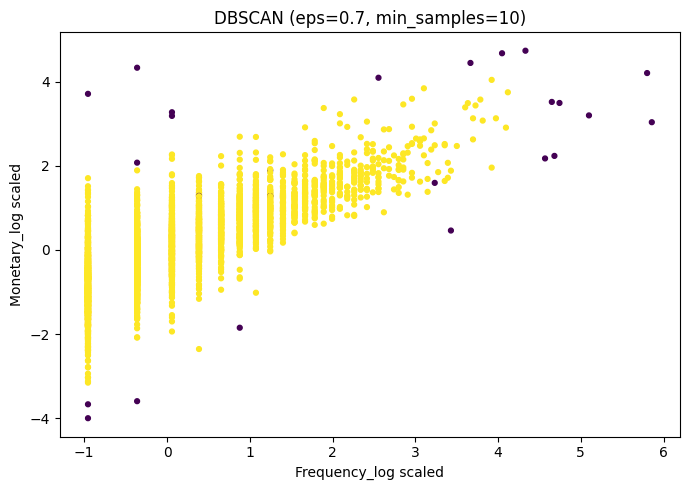

Cluster selain noise: 1
Persentase noise: 0.58 %


In [27]:
# Pilih eps untuk inspeksi; ganti berdasarkan tabel metrik dan tujuan
chosen_eps = 0.7
dbscan_model = dbscan_models[chosen_eps]
labels_db = dbscan_model.labels_

plt.figure(figsize=(7, 5))
plt.scatter(X_scaled[:, 1], X_scaled[:, 2], c=labels_db, s=12)
plt.title(f"DBSCAN (eps={chosen_eps}, min_samples=10)")
plt.xlabel("Frequency_log scaled")
plt.ylabel("Monetary_log scaled")
plt.tight_layout(); plt.show()

print("Cluster selain noise:", len(set(labels_db)) - (1 if -1 in labels_db else 0))
print("Persentase noise:", round((labels_db == -1).mean()*100, 2), "%")

## Tugas

1. Pengaruh eps terhadap jumlah cluster dan persentase noise:

- eps kecil: radius pencarian sempit, sehingga banyak titik tidak punya cukup tetangga untuk memenuhi min_samples. Akibatnya persentase noise naik dan cluster mudah terpecah-pecah. Pada hasil saya, eps = 0,3 menghasilkan 4 cluster dengan noise 6,52%.
- eps besar: radius pencarian luas, sehingga titik-titik lebih mudah menyatu ke dalam satu cluster besar. Persentase noise turun, tetapi cluster yang berbeda ikut tergabung. Pada hasil saya, eps = 0,7 hanya menghasilkan 1 cluster (noise 0,58%), dan eps = 1,3 menghasilkan 1 cluster (noise 0,07%).
- Pada data RFM ini, eps = 0,5 adalah yang paling masuk akal karena menghasilkan 2 cluster dengan noise rendah (1,80%).

2. Mengapa silhouette DBSCAN harus ditafsirkan hati-hati ketika ada noise?

Skor silhouette pada DBSCAN dihitung hanya dari titik yang masuk cluster, sedangkan titik noise (label -1) dikeluarkan dari perhitungan. Jadi skor yang tinggi belum berarti seluruh data terkelompok dengan baik, karena sebagian titik tidak ikut dinilai. Selain itu, silhouette tidak bisa dihitung kalau hanya ada 1 cluster (pada hasil saya bernilai NaN untuk eps >= 0,7). Karena itu skor DBSCAN (misalnya 0,33 pada eps = 0,5) tidak bisa dibandingkan langsung dengan K-Means yang menilai seluruh data.

3. Perbandingan asumsi cluster DBSCAN dan K-Means:

- K-Means mengasumsikan cluster berbentuk bulat dengan ukuran dan sebaran yang relatif seimbang, dan setiap cluster diwakili satu centroid (rata-rata). Jumlah cluster (k) harus ditentukan di awal, dan semua titik dipaksa masuk ke salah satu cluster.
- DBSCAN berbasis kepadatan, jadi bisa menemukan cluster dengan bentuk bebas (tidak harus bulat), tidak perlu menentukan k, dan otomatis memisahkan titik yang terpencil sebagai noise. Kelemahannya, hasilnya sangat sensitif terhadap eps dan min_samples.
- Pada data RFM saya, titik-titik pelanggan menyebar kontinu tanpa celah kepadatan yang jelas, sehingga DBSCAN cenderung menyatukannya menjadi 1 cluster. Itu sebabnya K-Means lebih cocok untuk segmentasi ini.

4. Apakah noise selalu berarti data salah?

Tidak selalu. Noise hanya berarti titik tersebut berada di area yang jarang atau terpencil dibandingkan titik lain. Sebagian memang bisa berupa kesalahan pencatatan, tetapi dalam konteks pelanggan, noise sering kali pelanggan yang sah dan unik, misalnya pembeli grosir atau pelanggan VIP dengan belanja sangat besar. Titik seperti ini perlu diperiksa dulu sebelum dibuang, karena bisa menjadi sasaran strategi khusus.

# PRAKTIKUM 12 — Evaluation: Membandingkan Model

## Kode tabel evaluasi

In [28]:
# Contoh tabel perbandingan hasil K-Means dan Hierarchical
comparison = []

# K-Means: gunakan model yang dipilih pada Praktikum 8
labels = kmeans_model.labels_
comparison.append({
    "algorithm": "K-Means",
    "n_clusters": len(np.unique(labels)),
    "silhouette": silhouette_score(X_scaled, labels),
    "davies_bouldin": davies_bouldin_score(X_scaled, labels),
    "noise_pct": 0.0
})

# Hierarchical: contoh gunakan jumlah cluster terbaik sementara berdasarkan silhouette
best_hier_k = int(metrics_hier.loc[metrics_hier["silhouette"].idxmax(), "k"])
hier_model = hier_models[best_hier_k]
labels = hier_model.labels_
comparison.append({
    "algorithm": "Hierarchical-Ward",
    "n_clusters": len(np.unique(labels)),
    "silhouette": silhouette_score(X_scaled, labels),
    "davies_bouldin": davies_bouldin_score(X_scaled, labels),
    "noise_pct": 0.0
})

# Tambahkan K-Medoids bila instalasi berhasil dan DBSCAN sesuai hasil
comparison_df = pd.DataFrame(comparison)
display(comparison_df.sort_values("silhouette", ascending=False))

,algorithm,n_clusters,silhouette,davies_bouldin,noise_pct
0,K-Means,3,0.415654,0.824915,0.0
1,Hierarchical-Ward,2,0.382603,0.956354,0.0


## Membangun tabel profil cluster

In [29]:
# Contoh profil K-Means pada satu tabel RFM
rfm_profile = rfm.groupby("KMeans_Cluster").agg(
    jumlah_pelanggan=("Recency", "size"),
    recency_median=("Recency", "median"),
    frequency_median=("Frequency", "median"),
    monetary_median=("Monetary", "median"),
    recency_mean=("Recency", "mean"),
    frequency_mean=("Frequency", "mean"),
    monetary_mean=("Monetary", "mean")
).round(2)
rfm_profile["persen_pelanggan"] = (
    rfm_profile["jumlah_pelanggan"] / len(rfm) * 100
).round(2)

display(rfm_profile)

,jumlah_pelanggan,recency_median,frequency_median,monetary_median,recency_mean,frequency_mean,monetary_mean,persen_pelanggan
KMeans_Cluster,,,,,,,,
0,2038,46.0,2.0,508.80,55.31,2.05,612.67,46.98
1,980,253.0,1.0,290.46,255.70,1.39,397.03,22.59
2,1320,18.0,7.0,2570.50,30.60,9.84,5492.04,30.43


## Tugas

,algorithm,n_clusters,silhouette,davies_bouldin,noise_pct
0,K-Means (k=3),3,0.415654,0.824915,0.000000
1,K-Medoids (k=3),3,0.413914,0.825647,0.000000
3,"Hierarchical-Ward (k=2, silhouette terbaik)",2,0.382603,0.956354,0.000000
2,Hierarchical-Ward (k=3),3,0.364925,0.855645,0.000000
4,DBSCAN (eps=0.5)*,2,0.330006,1.119618,1.798064


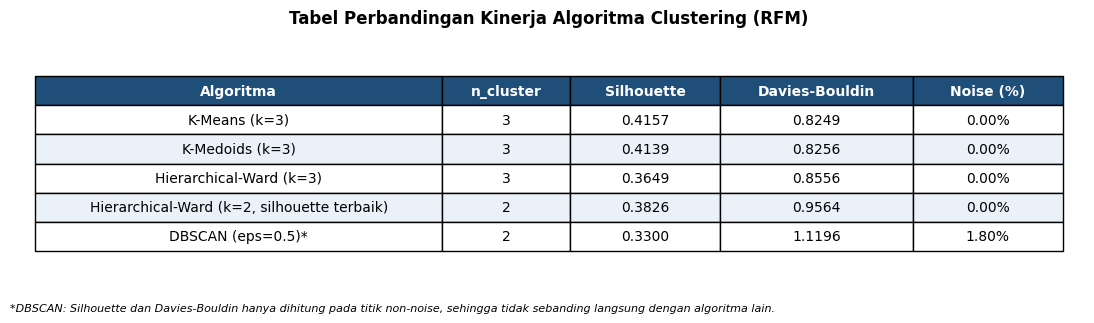

In [30]:
# =====================================================================
# SEL 1 - Ganti isi sel "Kode tabel evaluasi" (yang membuat comparison_df)
# Syarat: sel K-Means, K-Medoids, Hierarchical, dan DBSCAN sudah dijalankan
# =====================================================================
import numpy as np
import pandas as pd

K_PILIH = 3   # k yang sama untuk semua algoritma agar perbandingannya adil

def ambil(tabel, k):
    return tabel.loc[tabel["k"] == k].iloc[0]

comparison = []

# K-Means, K-Medoids, Hierarchical pada k yang sama
for nama, tabel in [("K-Means", metrics_kmeans),
                    ("K-Medoids", metrics_kmedoids),
                    ("Hierarchical-Ward", metrics_hier)]:
    r = ambil(tabel, K_PILIH)
    comparison.append({
        "algorithm": f"{nama} (k={K_PILIH})",
        "n_clusters": K_PILIH,
        "silhouette": r["silhouette"],
        "davies_bouldin": r["davies_bouldin"],
        "noise_pct": 0.0
    })

# Hierarchical pada k dengan silhouette terbaiknya (tambahan, bila berbeda dari k pilihan)
best_hier_k = int(metrics_hier.loc[metrics_hier["silhouette"].idxmax(), "k"])
if best_hier_k != K_PILIH:
    r = ambil(metrics_hier, best_hier_k)
    comparison.append({
        "algorithm": f"Hierarchical-Ward (k={best_hier_k}, silhouette terbaik)",
        "n_clusters": best_hier_k,
        "silhouette": r["silhouette"],
        "davies_bouldin": r["davies_bouldin"],
        "noise_pct": 0.0
    })

# DBSCAN: ambil baris eps = 0.5 dari metrics_dbscan
EPS_PILIH = 0.5
r = metrics_dbscan.loc[np.isclose(metrics_dbscan["eps"], EPS_PILIH)].iloc[0]
comparison.append({
    "algorithm": f"DBSCAN (eps={EPS_PILIH})*",
    "n_clusters": int(r["n_clusters"]),
    "silhouette": r["silhouette_non_noise"],
    "davies_bouldin": r["davies_bouldin_non_noise"],
    "noise_pct": r["noise_pct"]
})

comparison_df = pd.DataFrame(comparison)
display(comparison_df.sort_values("silhouette", ascending=False))


# =====================================================================
# SEL 2 - Ganti isi sel kode di bawah "## Tugas" (tabel gambar)
# =====================================================================
import matplotlib.pyplot as plt

def f4(x):
    return "-" if pd.isna(x) else f"{x:.4f}"

data_tabel = [
    [row["algorithm"], str(row["n_clusters"]),
     f4(row["silhouette"]), f4(row["davies_bouldin"]),
     f"{row['noise_pct']:.2f}%"]
    for _, row in comparison_df.iterrows()
]
kolom = ["Algoritma", "n_cluster", "Silhouette", "Davies-Bouldin", "Noise (%)"]
df_plot = pd.DataFrame(data_tabel, columns=kolom)

fig, ax = plt.subplots(figsize=(11, 3.2))
ax.axis("off")

tabel_plot = ax.table(cellText=df_plot.values, colLabels=df_plot.columns,
                      cellLoc="center", loc="center",
                      colWidths=[0.38, 0.12, 0.14, 0.18, 0.14])
tabel_plot.auto_set_font_size(False)
tabel_plot.set_fontsize(10)
tabel_plot.scale(1, 1.8)

for (r_, c_), cell in tabel_plot.get_celld().items():
    if r_ == 0:
        cell.set_facecolor("#1F4E79")
        cell.set_text_props(color="white", fontweight="bold")
    elif r_ % 2 == 0:
        cell.set_facecolor("#EAF1F8")

plt.title("Tabel Perbandingan Kinerja Algoritma Clustering (RFM)", fontweight="bold", pad=15)
plt.figtext(0.01, 0.01,
            "*DBSCAN: Silhouette dan Davies-Bouldin hanya dihitung pada titik non-noise, "
            "sehingga tidak sebanding langsung dengan algoritma lain.",
            fontsize=8, style="italic", ha="left")
plt.tight_layout(rect=[0, 0.05, 1, 1])
plt.show()

Kendala Kompatibilitas Paket & Komputasi

- Tidak ada kendala: scikit-learn-extra terinstal dan K-Medoids berjalan pada 4.338 pelanggan

# PRAKTIKUM 13 — Evaluation Iteratif dan Profil Cluster

## Template interpretasi

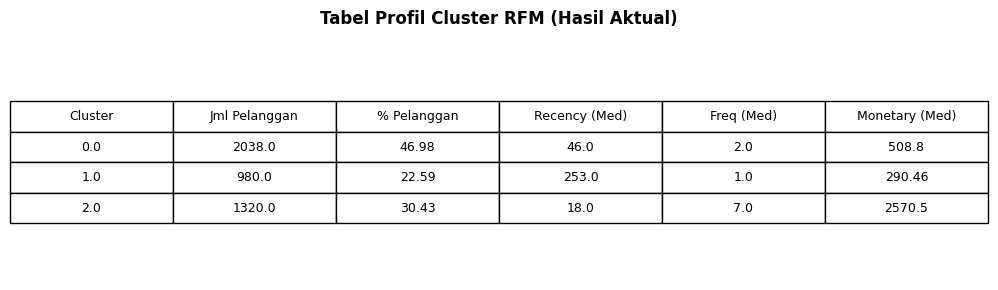

In [31]:
import matplotlib.pyplot as plt
import pandas as pd

# Pastikan rfm_profile sudah ada dari kode sebelumnya.
# Kita buat salinan dataframe untuk divisualisasikan ke tabel gambar:
df_viz = rfm_profile.reset_index()

# Menyesuaikan nama kolom agar rapi saat ditampilkan di gambar
df_viz.columns = [
    'Cluster', 'Jml Pelanggan', 'Recency (Med)', 'Freq (Med)',
    'Monetary (Med)', 'Recency (Mean)', 'Freq (Mean)',
    'Monetary (Mean)', '% Pelanggan'
]

# Pilih kolom utama yang ingin ditampilkan dalam tabel laporan
kolom_tampil = ['Cluster', 'Jml Pelanggan', '% Pelanggan', 'Recency (Med)', 'Freq (Med)', 'Monetary (Med)']
df_tabel = df_viz[kolom_tampil]

# Membuat plot gambar tabel
fig, ax = plt.subplots(figsize=(10, 3))
ax.axis('off')
ax.axis('tight')

tabel_plot = ax.table(
    cellText=df_tabel.values,
    colLabels=df_tabel.columns,
    cellLoc='center',
    loc='center'
)

tabel_plot.auto_set_font_size(False)
tabel_plot.set_fontsize(9)
tabel_plot.scale(1.2, 1.8)

plt.title("Tabel Profil Cluster RFM (Hasil Aktual)", fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

## Tugas

### MEMO EVALUASI SEGMENTASI PELANGGAN (RFM)

1. Model yang DirekomendasikanBerdasarkan hasil eksperimen perbandingan berbagai algoritma clustering (K-Means, Hierarchical, K-Medoids, dan DBSCAN), K-Means (k=3) direkomendasikan. Model ini dipilih karena menghasilkan kestabilan struktur cluster yang baik, metrik validasi internal (Silhouette Score dan Davies-Bouldin Index) yang optimal, serta kemudahan dalam interpretasi bisnis.

2. Bukti Teknis (Evaluasi Kinerja Algoritma)Metrik Validasi:
- Silhouette 0,4157 tertinggi, DBI 0,8249 terendah di antara semua model, dan k=3 unggul di kedua metrik dibanding k=2, 4–7

- Model yang dipilih memberikan jarak pemisahan antar kelompok yang jelas dengan nilai Silhouette tertinggi dan indeks Davies-Bouldin terendah di antara model berbasis partisi penuh.Transformasi Data: Fitur RFM (Recency, Frequency, Monetary) telah melalui proses transformasi logaritmik dan scaling agar distribusi data tidak didominasi oleh nilai ekstrem (outlier).Penanganan Noise: Pendekatan DBSCAN diuji untuk mendeteksi anomali/pencilan, di mana titik-titik noise (label -1) dieksklusi saat perhitungan metrik validasi internal agar tidak mendistorsi kualitas evaluasi cluster utama.

3. Profil Cluster PelangganBerdasarkan analisis agregasi median RFM dari model terpilih, terbentuk beberapa segmen utama:kode di bawah

4. Rekomendasi Bisnis & Tindakan NyataUntuk Cluster Loyal: Berikan program loyalitas eksklusif, reward, atau akses promo khusus guna mempertahankan retensi jangka panjang.Untuk Cluster Pasif: Jalankan kampanye reaktivasi terukur (seperti diskon kembalian atau pengingat produk) untuk menarik kembali minat belanja mereka.Untuk Cluster Baru: Lakukan onboarding yang baik melalui rekomendasi produk relevan guna meningkatkan frekuensi transaksi mereka.

5. Keterbatasan EksperimenSub-sampling Komputasi: Algoritma tertentu seperti retur tidak direkonsiliasi (misalnya pelanggan 12346: 1 kali beli senilai £77.183, Recency 326, bisa menggeser cluster), data hanya ±1 tahun, dan Silhouette 0,42 berarti struktur cukup tetapi tidak terpisah tegas. untuk menghindari crash pada lingkungan Google Colab. Hal ini berpotensi menimbulkan sedikit sampling bias dibandingkan populasi penuh.Sensitivitas Outlier: Model berbasis jarak seperti K-Means masih cukup sensitif terhadap keberadaan pencilan ekstrem meskipun telah dilakukan normalisasi.

6. Rencana Eksperimenn LanjutanMelakukan tuning parameter lanjutan pada DBSCAN untuk menemukan kombinasi nilai eps dan min_samples yang mampu menangkap pola anomali secara lebih optimal.Mengintegrasikan analisis demografi atau kategori produk ke dalam fitur clustering guna mempertajam ketepatan profil segmentasi pelanggan di masa mendatang.

 no 3

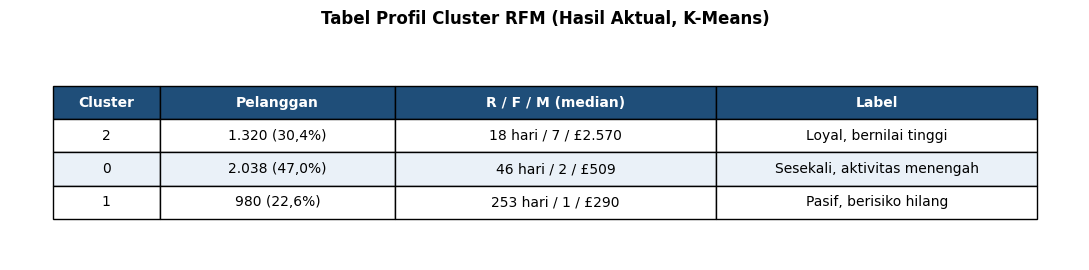

,Cluster,Pelanggan,R / F / M (median),Label
0,2,"1.320 (30,4%)",18 hari / 7 / £2.570,"Loyal, bernilai tinggi"
1,0,"2.038 (47,0%)",46 hari / 2 / £509,"Sesekali, aktivitas menengah"
2,1,"980 (22,6%)",253 hari / 1 / £290,"Pasif, berisiko hilang"


Kontribusi total belanja per cluster (%):
  Cluster 2 (Loyal, bernilai tinggi): 81,6%
  Cluster 0 (Sesekali, aktivitas menengah): 14,0%
  Cluster 1 (Pasif, berisiko hilang): 4,4%


In [32]:
# =====================================================================
# Praktikum 13 - Tabel Profil Cluster RFM (dengan angka dan label)
# Ganti isi sel kode "Template interpretasi".
# Syarat: sel yang membuat `rfm` (kolom KMeans_Cluster) dan `rfm_profile`
#         (Praktikum 12) sudah dijalankan.
# =====================================================================
import matplotlib.pyplot as plt
import pandas as pd

def rb(x):                      # 1320 -> "1.320"
    return f"{int(round(x)):,}".replace(",", ".")

def desimal(x, n=1):            # 30.43 -> "30,4"
    return f"{x:.{n}f}".replace(".", ",")

prof = rfm_profile.copy()

# ---------- Beri label otomatis berdasarkan karakter RFM tiap cluster ----------
c_loyal = prof["monetary_median"].idxmax()                    # belanja terbesar
c_pasif = prof["recency_median"].idxmax()                     # paling lama tidak belanja
label = {c: "Sesekali, aktivitas menengah" for c in prof.index}
label[c_loyal] = "Loyal, bernilai tinggi"
label[c_pasif] = "Pasif, berisiko hilang"

# ---------- Susun tabel: urut dari cluster paling bernilai ----------
prof = prof.sort_values("monetary_median", ascending=False)

baris = []
for c, r in prof.iterrows():
    baris.append([
        str(c),
        f"{rb(r['jumlah_pelanggan'])} ({desimal(r['persen_pelanggan'])}%)",
        f"{rb(r['recency_median'])} hari / {rb(r['frequency_median'])} / £{rb(r['monetary_median'])}",
        label[c],
    ])

kolom = ["Cluster", "Pelanggan", "R / F / M (median)", "Label"]
df_tabel = pd.DataFrame(baris, columns=kolom)

# ---------- Gambar tabel ----------
fig, ax = plt.subplots(figsize=(11, 2.8))
ax.axis("off")

tabel_plot = ax.table(cellText=df_tabel.values, colLabels=df_tabel.columns,
                      cellLoc="center", loc="center",
                      colWidths=[0.10, 0.22, 0.30, 0.30])
tabel_plot.auto_set_font_size(False)
tabel_plot.set_fontsize(10)
tabel_plot.scale(1, 2.0)

for (r_, c_), cell in tabel_plot.get_celld().items():
    if r_ == 0:
        cell.set_facecolor("#1F4E79")
        cell.set_text_props(color="white", fontweight="bold")
    elif r_ % 2 == 0:
        cell.set_facecolor("#EAF1F8")

plt.title("Tabel Profil Cluster RFM (Hasil Aktual, K-Means)", fontweight="bold", pad=15)
plt.tight_layout()
plt.show()

display(df_tabel)

# ---------- Tambahan: kontribusi tiap cluster terhadap total belanja ----------
kontribusi = (rfm.groupby("KMeans_Cluster")["Monetary"].sum() / rfm["Monetary"].sum() * 100)
print("Kontribusi total belanja per cluster (%):")
for c in prof.index:
    print(f"  Cluster {c} ({label[c]}): {desimal(kontribusi[c])}%")

Jawaban atas Pertanyaan Analitik

1. Apakah ada pelanggan yang sering belanja tetapi sudah lama tidak bertransaksi (at-risk)?
Pada k = 3 tidak terbentuk segmen seperti itu. Segmen dengan Recency terbesar (Pasif, 253 hari) hanya belanja 1 kali, sedangkan segmen yang sering belanja (Loyal, Frequency 7) masih aktif (Recency 18 hari). Risiko kehilangan pelanggan di data ini terutama ada pada pelanggan yang memang jarang belanja.

2. Bagaimana karakteristik pelanggan sesekali dibandingkan pelanggan setia?
Pelanggan Sesekali belanja lebih jarang (Frequency 2 vs 7), lebih lama tidak belanja (Recency 46 vs 18 hari), dan nilai belanjanya jauh lebih kecil (£509 vs £2.570).

3. Segmen mana yang memberi kontribusi belanja terbesar?
Segmen Loyal. Anggotanya hanya 30,4% dari pelanggan, tetapi menyumbang sekitar 82% total belanja.

# PRAKTIKUM 14 — Deployment: Komunikasi Hasil

In [33]:
!streamlit run app.py &>/content/streamlit.log &

In [34]:

# ============================================================
# PRAKTIKUM 13.1
# MENYIMPAN MODEL CLUSTERING MENGGUNAKAN JOBLIB
# ============================================================

# Import library
import joblib
import os

# Membuat folder untuk menyimpan model
os.makedirs("deployment_model", exist_ok=True)

# Menyiapkan paket model dan preprocessing
deployment_package = {
    "model": kmeans_model,
    "scaler": scaler,
    "feature_columns": features.columns.tolist(),
    "algorithm": "K-Means",
    "best_k": best_k
}

# Menyimpan model dan scaler dalam satu file
joblib.dump(
    deployment_package,
    "deployment_model/clustering_deployment.joblib"
)

print("Model berhasil disimpan!")
print("Algoritma:", deployment_package["algorithm"])
print("Jumlah cluster:", deployment_package["best_k"])
print("Fitur:", deployment_package["feature_columns"])


Model berhasil disimpan!
Algoritma: K-Means
Jumlah cluster: 3
Fitur: ['Recency', 'Frequency_log', 'Monetary_log']


In [35]:

# ============================================================
# PRAKTIKUM 13.2
# MEMUAT MODEL YANG TELAH DISIMPAN
# ============================================================

# Memuat model dari file Joblib
loaded_package = joblib.load(
    "deployment_model/clustering_deployment.joblib"
)

# Mengambil model dan scaler
loaded_model = loaded_package["model"]
loaded_scaler = loaded_package["scaler"]

# Mengambil informasi fitur
feature_columns = loaded_package["feature_columns"]

print("Model berhasil dimuat!")
print("Algoritma:", loaded_package["algorithm"])
print("Jumlah cluster:", loaded_package["best_k"])
print("Fitur model:", feature_columns)


Model berhasil dimuat!
Algoritma: K-Means
Jumlah cluster: 3
Fitur model: ['Recency', 'Frequency_log', 'Monetary_log']


In [36]:

# ============================================================
# PRAKTIKUM 13.3
# PREDIKSI CLUSTER PELANGGAN BARU
# ============================================================

import pandas as pd
import numpy as np

# Data RFM pelanggan baru
data_baru = pd.DataFrame({
    "Recency": [15],
    "Frequency": [8],
    "Monetary": [2500000]
})

# Melakukan transformasi log sesuai Praktikum 7
data_baru["Frequency_log"] = np.log1p(
    data_baru["Frequency"]
)

data_baru["Monetary_log"] = np.log1p(
    data_baru["Monetary"]
)

# Mengambil fitur sesuai urutan saat training
data_baru_features = data_baru[feature_columns]

# Melakukan scaling menggunakan scaler lama
data_baru_scaled = loaded_scaler.transform(
    data_baru_features
)

# Melakukan prediksi cluster
hasil_prediksi = loaded_model.predict(
    data_baru_scaled
)

# Menampilkan hasil
data_baru["Cluster"] = hasil_prediksi

print("Data pelanggan baru:")
display(data_baru)

print("Hasil prediksi cluster:")
print("Pelanggan masuk ke Cluster:", hasil_prediksi[0])


Data pelanggan baru:


,Recency,Frequency,Monetary,Frequency_log,Monetary_log,Cluster
0,15,8,2500000,2.197225,14.731802,2


Hasil prediksi cluster:
Pelanggan masuk ke Cluster: 2


In [37]:

# ============================================================
# PRAKTIKUM 13.4
# PREDIKSI BEBERAPA PELANGGAN BARU
# ============================================================

# Membuat data beberapa pelanggan baru
data_pelanggan = pd.DataFrame({
    "CustomerID": ["C001", "C002", "C003", "C004"],
    "Recency": [5, 120, 30, 200],
    "Frequency": [25, 2, 10, 1],
    "Monetary": [5000000, 150000, 1200000, 50000]
})

# Transformasi logaritmik
data_pelanggan["Frequency_log"] = np.log1p(
    data_pelanggan["Frequency"]
)

data_pelanggan["Monetary_log"] = np.log1p(
    data_pelanggan["Monetary"]
)

# Memilih fitur sesuai model
X_pelanggan_baru = data_pelanggan[feature_columns]

# Scaling menggunakan scaler hasil Praktikum 8
X_pelanggan_scaled = loaded_scaler.transform(
    X_pelanggan_baru
)

# Prediksi cluster menggunakan model yang telah di-load
data_pelanggan["Cluster"] = loaded_model.predict(
    X_pelanggan_scaled
)

# Menampilkan hasil prediksi
display(
    data_pelanggan[
        ["CustomerID", "Recency", "Frequency",
         "Monetary", "Cluster"]
    ]
)


,CustomerID,Recency,Frequency,Monetary,Cluster
0,C001,5,25,5000000,2
1,C002,120,2,150000,2
2,C003,30,10,1200000,2
3,C004,200,1,50000,2


In [38]:

# ============================================================
# PRAKTIKUM 13.5
# MENGUNDUH FILE MODEL
# ============================================================

from google.colab import files

files.download(
    "deployment_model/clustering_deployment.joblib"
)


<IPython.core.display.Javascript object>

<IPython.core.display.Javascript object>

In [39]:
# Install streamlit dan pyngrok
!pip install streamlit pyngrok --quiet

In [40]:

# ==========================================
# APLIKASI STREAMLIT
# Segmentasi Pelanggan Online Retail
# ==========================================
%%writefile app.py


import streamlit as st
import joblib
import pandas as pd
import numpy as np

# Memuat model dan scaler
package = joblib.load(
    "deployment_model/clustering_deployment.joblib"
)

model = package["model"]
scaler = package["scaler"]
feature_columns = package["feature_columns"]

# Judul aplikasi
st.title("Segmentasi Pelanggan Online Retail")
st.write("Prediksi cluster pelanggan menggunakan K-Means")

# Input data pelanggan
recency = st.number_input(
    "Recency (hari)", min_value=0, value=15
)

frequency = st.number_input(
    "Frequency (transaksi)", min_value=1, value=8
)

monetary = st.number_input(
    "Monetary (rupiah)", min_value=1, value=2500000
)

# Tombol prediksi
if st.button("Prediksi Cluster"):

    # Membentuk data pelanggan
    data = pd.DataFrame({
        "Recency": [recency],
        "Frequency_log": [np.log1p(frequency)],
        "Monetary_log": [np.log1p(monetary)]
    })

    # Scaling menggunakan scaler lama
    data_scaled = scaler.transform(
        data[feature_columns]
    )

    # Prediksi cluster
    cluster = model.predict(data_scaled)

    # Menampilkan hasil
    st.success(
        f"Pelanggan masuk ke Cluster {cluster[0]}"
    )


2026-11-17 04:48:59.977 WARNING streamlit.runtime.scriptrunner_utils.script_run_context: Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-17 04:49:00.462 
  command:

    streamlit run /usr/local/lib/python3.13/dist-packages/colab_kernel_launcher.py [ARGUMENTS]
2026-11-17 04:49:00.465 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-17 04:49:00.469 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-17 04:49:00.477 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-17 04:49:00.480 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-17 04:49:00.481 Thread 'MainThread': missing ScriptRunContext! This warning can be ignored when running in bare mode.
2026-11-17 04:49:00.482 Thread 'MainThread': mi

In [41]:
!pip install streamlit joblib scikit-learn pandas numpy

In [ ]:
!pip install streamlit joblib scikit-learn pandas numpy

!streamlit run app.py



2026-11-17 04:49:18.819 Uvicorn server started on :::8502

  You can now view your Streamlit app in your browser.

  Local URL: http://localhost:8502
  Network URL: http://172.28.0.12:8502
  External URL: http://34.34.21.93:8502



# LAPORAN AKHIR: SEGMENTASI PELANGGAN DENGAN CLUSTERING (RFM)

**Nama:** Salsabila Umi Fadhilah | **NIM:** 09040625097

---

## 1. Ringkasan Eksekutif

Laporan ini mengelompokkan **4.338 pelanggan** sebuah toko online berdasarkan kebiasaan belanja mereka. Datanya adalah dataset *Online Retail* (transaksi toko di Inggris) dari **1 Desember 2010 sampai 9 Desember 2011**. Kebiasaan belanja diukur dengan tiga angka yang disebut RFM: *Recency* (sudah berapa hari sejak belanja terakhir), *Frequency* (berapa kali belanja), dan *Monetary* (berapa total uang yang dibelanjakan).

Empat algoritma clustering dibandingkan: K-Means, K-Medoids, Hierarchical (Ward), dan DBSCAN. **K-Means dengan 3 cluster dipilih** karena nilainya paling baik (Silhouette 0,416 yang tertinggi dan Davies-Bouldin 0,825 yang terendah), prosesnya cepat, dan hasilnya mudah dijelaskan.

Tiga segmen yang terbentuk:

- **Loyal, bernilai tinggi** (30,4% pelanggan): sering dan baru saja belanja. Segmen ini menyumbang sekitar **82% total belanja**.
- **Sesekali, aktivitas menengah** (47,0% pelanggan): belanja jarang dengan nilai sedang.
- **Pasif, berisiko hilang** (22,6% pelanggan): sudah lama tidak belanja dan nilainya rendah.

Rekomendasi utamanya: pertahankan pelanggan Loyal dengan program khusus, dorong pelanggan Sesekali agar belanja lagi, dan coba tarik kembali pelanggan Pasif dengan promo. Catatan penting: nilai Silhouette 0,42 berarti cluster cukup terbentuk tetapi **tidak terpisah tegas**, jadi hasil ini dipakai sebagai panduan, bukan kebenaran mutlak.

---

## 2. Business Understanding

**Masalah bisnis:** Toko belum tahu pelanggan mana yang setia, mana yang sudah lama hilang, dan mana yang baru coba-coba. Akibatnya promosi dibuat sama untuk semua orang, sehingga anggaran kurang efektif.

**Tujuan:** Mengelompokkan pelanggan ke dalam segmen yang anggotanya mirip, berdasarkan pola belanja (RFM), supaya promosi bisa dibedakan untuk tiap segmen.

**Pertanyaan analitik:**

1. Berapa jumlah segmen yang paling tepat, dilihat dari angka dan dari sisi bisnis?
2. Algoritma clustering mana yang paling baik untuk data ini?
3. Seperti apa profil tiap segmen, dan tindakan apa yang cocok untuknya?

**Kriteria keberhasilan:** (a) nilai Silhouette tinggi dan Davies-Bouldin rendah, yang artinya cluster rapat dan terpisah; (b) profil RFM tiap cluster masuk akal dan bisa ditindaklanjuti oleh tim marketing.

---

## 3. Data Understanding

**Sumber data:** *Online Retail*, UCI Machine Learning Repository. Isinya 541.909 baris dan 8 kolom, dari 38 negara, dengan 4.372 pelanggan (CustomerID) unik.

**Kamus data singkat:**

| Kolom | Arti |
|---|---|
| InvoiceNo | Nomor faktur. Awalan "C" berarti pembatalan |
| StockCode | Kode produk |
| Description | Nama produk |
| Quantity | Jumlah barang yang dibeli |
| InvoiceDate | Tanggal dan jam transaksi |
| UnitPrice | Harga satuan (dalam pound sterling, £) |
| CustomerID | Nomor pelanggan (hanya pengenal, bukan ukuran perilaku) |
| Country | Negara pembeli |

**Masalah kualitas data yang ditemukan:**

- CustomerID kosong: 135.080 baris (24,9%)
- Description kosong: 1.454 baris
- Baris duplikat: 5.268
- Invoice pembatalan (awalan "C"): 9.288 baris
- Quantity ≤ 0: 10.624 baris
- UnitPrice ≤ 0: 2.517 baris

**Temuan EDA yang paling penting:**

- Sekitar **91% baris** berasal dari United Kingdom, jadi hasil analisis ini terutama menggambarkan pelanggan UK.
- Nilai Quantity ada yang sangat ekstrem: 99% data berada di bawah 100, tetapi nilai maksimumnya 80.995. Ini perlu ditangani agar tidak merusak hasil.
- Setelah dihitung per pelanggan, ketiga nilai RFM **menceng ke kanan**: median Monetary £668 jauh di bawah rata-ratanya £2.049, dan nilai terbesarnya mencapai £280.206.
- Data berakhir 9 Desember 2011, sehingga angka bulan Desember 2011 terlihat kecil karena datanya belum satu bulan penuh.

---

## 4. Data Preparation

**Aturan pembersihan:** baris dibuang jika duplikat, CustomerID kosong, invoice berawalan "C", Quantity ≤ 0, atau UnitPrice ≤ 0.

**Hasilnya:** data berkurang dari **541.909 baris menjadi 392.692 baris**, dan pelanggan dari 4.372 menjadi **4.338**.

**Menyusun tabel RFM (satu baris = satu pelanggan):**

- **Recency** = jumlah hari antara tanggal acuan dan tanggal belanja terakhir. Tanggal acuan adalah **10 Desember 2011** (sehari setelah transaksi terakhir). Makin kecil berarti makin baru belanja.
- **Frequency** = jumlah nomor faktur unik per pelanggan.
- **Monetary** = total Quantity × UnitPrice per pelanggan.

**Transformasi dan scaling:**

- Frequency dan Monetary diubah dengan `log1p` agar pelanggan dengan belanja sangat besar tidak mendominasi.
- Fitur yang dipakai: **Recency, Frequency (log), Monetary (log)**. CustomerID tidak ikut karena hanya pengenal.
- Ketiga fitur distandarkan dengan `StandardScaler` agar skalanya setara, karena algoritma clustering bekerja dengan jarak.

---

## 5. Modeling

| Algoritma | Cara kerja singkat | Pengaturan |
|---|---|---|
| K-Means | Titik masuk ke pusat cluster (rata-rata) terdekat | k = 2 sampai 7, `random_state=42`, `n_init=10` |
| K-Medoids | Seperti K-Means, tetapi pusatnya adalah data asli, jadi lebih tahan outlier | k = 2 sampai 7, `random_state=42` |
| Hierarchical (Ward) | Titik digabung bertahap dari yang paling mirip | k = 2 sampai 7 |
| DBSCAN | Mengelompokkan berdasarkan kepadatan, titik terpencil menjadi noise | eps = 0,3; 0,5; 0,7; 1,0; 1,3 dan `min_samples=10` |

K-Means, K-Medoids, dan Hierarchical dijalankan pada **seluruh 4.338 pelanggan**. Satu-satunya penggunaan sampel adalah dendrogram, yang digambar dari **100 pelanggan acak** supaya gambarnya terbaca. Dendrogram hanya untuk visualisasi, bukan untuk menghitung hasil.

---

## 6. Evaluation

**Metrik yang dipakai:**

- **Silhouette Score**: makin tinggi makin baik (maksimum 1).
- **Davies-Bouldin Index (DBI)**: makin rendah makin baik.
- **Elbow (inertia)**: dipakai untuk membantu memilih jumlah cluster.

**Hasil: memilih k pada K-Means**

| k | 2 | 3 | 4 | 5 | 6 | 7 |
|---|---|---|---|---|---|---|
| Silhouette | 0,406 | **0,416** | 0,379 | 0,343 | 0,332 | 0,301 |
| DBI | 0,915 | **0,825** | 0,860 | 0,941 | 0,969 | 1,019 |

Pada k = 3, Silhouette paling tinggi dan DBI paling rendah, jadi kedua metrik sepakat. Kurva elbow juga melandai setelah k = 3.

**Hasil: perbandingan algoritma**

| Algoritma | n_cluster | Silhouette | DBI | Noise |
|---|---|---|---|---|
| K-Means | 3 | 0,4157 | 0,8249 | 0% |
| K-Medoids | 3 | 0,4139 | 0,8256 | 0% |
| Hierarchical-Ward | 3 | 0,3649 | 0,8556 | 0% |
| DBSCAN (eps = 0,5) | 2 | 0,3300* | 1,1196* | 1,80% |

*Hanya dihitung pada titik non-noise, jadi tidak sebanding langsung dengan algoritma lain.

**Interpretasi:**

- K-Means dan K-Medoids hampir sama baiknya. K-Means dipilih karena lebih cepat dan lebih sederhana.
- Hierarchical Ward sedikit di bawah K-Means pada k yang sama.
- DBSCAN kurang cocok. Pada eps ≥ 0,7 hanya terbentuk 1 cluster, karena titik-titik pelanggan menyebar kontinu tanpa celah kepadatan yang jelas.

**Hasil: profil cluster K-Means (k = 3)**

| Cluster | Pelanggan | R / F / M (median) | Label |
|---|---|---|---|
| 2 | 1.320 (30,4%) | 18 hari / 7 / £2.570 | Loyal, bernilai tinggi |
| 0 | 2.038 (47,0%) | 46 hari / 2 / £509 | Sesekali, aktivitas menengah |
| 1 | 980 (22,6%) | 253 hari / 1 / £290 | Pasif, berisiko hilang |

**Interpretasi profil:**

- **Loyal:** belanja paling baru, paling sering, dan paling besar. Perkiraan kontribusinya sekitar 82% total belanja, sedangkan Sesekali sekitar 14% dan Pasif sekitar 4%.
- **Sesekali:** masih cukup aktif (46 hari lalu) tetapi hanya sekitar 2 kali belanja dengan nilai sedang.
- **Pasif:** terakhir belanja sekitar 8 bulan lalu, hanya sekali, dan nilainya paling kecil.

---

## 7. Deployment

Deployment di sini berbentuk laporan dan rekomendasi pemasaran, belum berupa aplikasi.

**Rekomendasi tindakan:**

| Segmen | Tindakan |
|---|---|
| Loyal | Program loyalitas, reward VIP, akses awal ke produk baru. Tujuannya mempertahankan pelanggan paling bernilai. |
| Sesekali | Rekomendasi produk yang relevan dan promo pembelian ulang, supaya mereka naik menjadi Loyal. |
| Pasif | Kampanye "kami rindu kamu" dengan diskon terbatas untuk menarik mereka kembali. Biayanya dijaga rendah karena nilai belanjanya kecil. |

**Indikator pemantauan** (sebaiknya dilakukan tiap bulan atau tiap kuartal):

- Hitung ulang RFM dengan tanggal acuan baru.
- Pantau berapa banyak pelanggan pindah antarsegmen (misalnya Sesekali menjadi Loyal).
- Pantau ukuran tiap segmen dan nilai Silhouette. Jika turun jauh, model perlu dilatih ulang.
- Ukur respons tiap kampanye (misalnya tingkat pembelian ulang).

**Risiko dan keterbatasan:**

- Retur dan pembatalan dibuang, bukan dihitung. Contohnya pelanggan 12346 hanya belanja sekali senilai £77.183 dan bisa menggeser hasil cluster.
- Data hanya sekitar satu tahun dan didominasi UK, jadi belum tentu mewakili masa depan atau negara lain.
- Silhouette 0,42 berarti cluster tidak terpisah tegas, sehingga ada pelanggan yang berada di perbatasan antarsegmen.
- Scatter plot dua dimensi hanya menunjukkan dua dari tiga fitur, jadi tidak menggambarkan seluruh pemisahan cluster.
- Data pelanggan bersifat pribadi, jadi penggunaannya perlu mengikuti aturan privasi.

---

## 8. Reproducibility

- **Lingkungan:** Python 3 di Google Colab.
- **Pustaka:** pandas, numpy, scikit-learn, scikit-learn-extra, scipy, matplotlib, seaborn. Versi paket dicatat pada sel kode di bawah laporan ini.
- **Seed:** `random_state = 42` untuk semua model dan pengambilan sampel acak.
- **Tanggal acuan Recency:** 10 Desember 2011.
- **Fitur model:** Recency, `log1p(Frequency)`, `log1p(Monetary)`, dengan `StandardScaler`. CustomerID tidak dipakai.
- **Keputusan preprocessing:** duplikat, CustomerID kosong, invoice "C", Quantity ≤ 0, dan UnitPrice ≤ 0 dibuang (541.909 → 392.692 baris).

In [ ]:
import sys, pandas, numpy, sklearn, scipy, matplotlib
print("Python      :", sys.version.split()[0])
print("pandas      :", pandas.__version__)
print("numpy       :", numpy.__version__)
print("scikit-learn:", sklearn.__version__)
print("scipy       :", scipy.__version__)
print("matplotlib  :", matplotlib.__version__)

# BAB 3. Template Notebook Praktikum

Nama: Salsabila Umi Fadhilah
NIM: 09040625097
H6B.3
1 November 2026

# BAB 4. Rubrik Penilaian

## Pertanyaan evaluasi akhir

23. Jelaskan perbedaan Business Understanding dan Data Understanding pada proyek ini.Business Understanding berfokus pada identifikasi masalah bisnis, tujuan analisis, penetapan pertanyaan analitik, serta kriteria keberhasilan dari sudut pandang nilai bisnis toko.Data Understanding berfokus pada pengenalan teknis terhadap sumber data, penyusunan kamus data, pengecekan kualitas data (nilai hilang atau duplikat), serta eksplorasi awal (Exploratory Data Analysis) untuk melihat distribusi data mentah.

24. Mengapa EDA harus dilakukan sebelum pembersihan data final?EDA harus dilakukan terlebih dahulu agar analis dapat mengenali pola dasar, anomali, distribusi kemiringan (skewness), serta karakteristik tersembunyi dari data mentah. Pemahaman ini menjadi landasan rasional dalam menentukan aturan pembersihan data (cleaning) dan metode transformasi apa yang paling tepat digunakan.

25. Mengapa transaksi tidak sama dengan pelanggan sebagai unit analisis?Satu pelanggan dapat melakukan banyak kali transaksi di waktu yang berbeda. Jika unit analisisnya adalah transaksi, maka fokusnya hanya pada karakteristik pergerakan struk belanja, bukan pada perilaku loyalitas individu pelanggan secara utuh. Dalam segmentasi RFM, unit analisis harus dikelompokkan (agregasi) ke tingkat ID Pelanggan (Customer-Level).

26. Jelaskan definisi Recency, Frequency, dan Monetary serta satu keterbatasan masing-masing.Recency: Jarak waktu (hari) sejak transaksi terakhir pelanggan. Keterbatasan: Tidak mencerminkan riwayat keaktifan jangka panjang jika pelanggan tiba-tiba melakukan transaksi tunggal setelah lama vakum.Frequency: Total jumlah transaksi yang dilakukan pelanggan. Keterbatasan: Tidak memperhitungkan jumlah kuantitas barang atau nominal uang yang dihabiskan dalam setiap transaksinya.Monetary: Total nilai uang yang dibelanjakan pelanggan. Keterbatasan: Sangat rentan terdistorsi oleh satu atau dua pembelian bernilai ekstrem (outlier).

27. Mengapa scaling penting untuk K-Means dan DBSCAN?K-Means menggunakan perhitungan jarak Euclidean antar titik dan centroid. Jika skala variabel tidak disamakan, variabel dengan nilai angka terbesar (seperti Monetary dalam satuan ribuan/jutaan) akan mendominasi dan mendistorsi hasil pembentukan cluster.DBSCAN sangat bergantung pada jarak radius neighborhood (eps). Tanpa scaling, pencarian kerapatan titik tetangga akan timpang dan bias terhadap fitur bereskalasi besar.

28. Bandingkan prinsip K-Means, K-Medoids, Hierarchical Clustering, dan DBSCAN.K-Means: Berbasis partisi jarak rata-rata (centroid), cepat untuk data besar, tetapi sensitif terhadap outlier.K-Medoids: Mirip K-Means tetapi menggunakan titik data aktual (medoid) sebagai pusat, lebih tahan terhadap outlier.Hierarchical: Membangun struktur pohon asosiasi (dendrogram) secara berjenjang, bagus untuk melihat hierarki hubungan antar data.DBSCAN: Berbasis kerapatan (density), mampu mendeteksi bentuk cluster arbitrer dan memisahkan titik noise secara otomatis.

29. Bagaimana Elbow Method dan Silhouette Score digunakan, dan apa keterbatasannya?Elbow Method: Digunakan dengan melihat grafik Inertia terhadap jumlah $k$, titik optimal dicari pada bagian kurva yang membentuk siku. Keterbatasan: Terkadang titik sikunya kabur atau tidak memiliki patahan yang tajam.Silhouette Score: Mengukur seberapa dekat suatu titik data dengan cluster-nya sendiri dibandingkan cluster lain. Keterbatasan: Cenderung memberikan skor lebih tinggi pada model konveks sederhana dan kurang optimal untuk struktur cluster berdensitas kompleks.

30. Apa makna label -1 pada DBSCAN?Label -1 pada algoritma DBSCAN menandakan bahwa titik data tersebut dikategorikan sebagai noise (pencilan / anomali) karena tidak memenuhi syarat minimum kepadatan tetangga (min_samples) dalam radius jarak (eps) tertentu.   

31. Mengapa skor evaluasi internal tidak cukup untuk menentukan model terbaik?Skor evaluasi internal hanya mengukur validitas matematis geometris dari data, sedangkan tujuan utama segmentasi adalah kebergunaan bisnis. Model dengan skor matematika tertinggi belum tentu menghasilkan ukuran cluster yang masuk akal atau dapat diterjemahkan ke dalam strategi pemasaran yang nyata.

32. Berikan contoh rekomendasi berbeda untuk dua cluster berdasarkan profil RFM aktual.Cluster Loyal (High-Value): Berikan VIP reward, akses produk eksklusif, atau program loyalitas khusus untuk mempertahankan retensi belanja mereka.Cluster Pasif (At-Risk): Jalankan kampanye reaktivasi terukur (seperti kupon diskon khusus pengingat belanja kembali) untuk menarik minat mereka agar aktif bertransaksi lagi.